In [2]:
# ============================================================================
# Bee Toxicogenomics Data Analysis Script (Corrected)
# ============================================================================
# This script loads the two Excel files, performs comprehensive analyses,
# and generates summary tables and figures. It is designed for Google Colab.
# ============================================================================

# -------------------- 1. Install and import libraries --------------------
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files

# -------------------- 2. Upload files --------------------
print("Please upload the two Excel files:")
print("1. Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx")
print("2. Bee_Toxicogenomics_Data_Extraction_Completed.xlsx")

uploaded = files.upload()

# Assign file names
v2_filename = None
completed_filename = None
for fname in uploaded.keys():
    if 'v2' in fname.lower():
        v2_filename = fname
    elif 'Completed' in fname and 'v2' not in fname.lower():
        completed_filename = fname

if v2_filename is None:
    raise ValueError("The v2 file was not uploaded correctly.")
if completed_filename is None:
    print("Warning: The completed (non-v2) file was not uploaded. Proceeding with v2 only.")

# -------------------- 3. Load data --------------------
v2_sheets = pd.read_excel(v2_filename, sheet_name=None)
# The main data is in sheet "Completed Extraction v2" (or possibly "Sheet1")
v2_df = v2_sheets.get('Completed Extraction v2')
if v2_df is None:
    v2_df = v2_sheets.get('Sheet1')  # fallback
print(f"Loaded v2 data: {v2_df.shape[0]} rows, {v2_df.shape[1]} columns")

# Optional: load completed file for additional stats (if available)
if completed_filename:
    comp_sheets = pd.read_excel(completed_filename, sheet_name=None)
    comp_df = comp_sheets.get('Completed Extraction')
    if comp_df is None:
        comp_df = comp_sheets.get('Sheet1')
    print(f"Loaded completed data: {comp_df.shape[0]} rows")

# -------------------- 4. Preprocess: Create Study_type column ----------------
# If 'Study type' column is missing, derive it from 'Omics'
if 'Study type' not in v2_df.columns:
    print("'Study type' column not found. Creating from 'Omics' column.")
    # Define keywords for global omics
    global_terms = ['transcriptom', 'proteom', 'metabolom', 'epigenet', 'lipidom', 'multi-omics', 'mass spectrometry']
    def classify(row):
        omics = str(row.get('Omics', '')).lower()
        if any(term in omics for term in global_terms):
            return 'Type A: Global Omics'
        elif 'rt-qpcr' in omics or 'qpcr' in omics or 'targeted' in omics:
            return 'Type B: Targeted RT-qPCR'
        else:
            return 'Other'
    v2_df['Study_type'] = v2_df.apply(classify, axis=1)
else:
    print("'Study type' column found. Using as is.")

# Filter out rows that are not eligible (optional based on Status)
if 'Status' in v2_df.columns:
    # Exclude rows where Status indicates non-pesticide or reference validation
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded']
    eligible = ~v2_df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    v2_df = v2_df[eligible].copy()
    print(f"After filtering by Status, {len(v2_df)} rows remain.")

# -------------------- 5. Helper functions --------------------
def extract_systems(deg_col):
    """Extract System: labels from Key DEGs column (Type B studies)."""
    if pd.isna(deg_col):
        return []
    systems = re.findall(r'System:\s*([^;)]+)', str(deg_col))
    return systems

def extract_genes(deg_col):
    """Extract gene names from Key DEGs column (remove System tags)."""
    if pd.isna(deg_col):
        return []
    cleaned = re.sub(r'\(System:[^)]+\)', '', str(deg_col))
    genes = re.split(r'[;,/]\s*', cleaned)
    return [g.strip() for g in genes if g.strip()]

def categorize_duration(dur):
    if pd.isna(dur):
        return 'Unknown'
    dur_str = str(dur).lower()
    if 'h' in dur_str:
        hours = re.search(r'(\d+)\s*h', dur_str)
        if hours and int(hours.group(1)) <= 24:
            return 'Acute (≤24h)'
        else:
            return 'Subacute (>24h)'
    if 'day' in dur_str or 'd' in dur_str:
        return 'Chronic'
    return 'Other'

def extract_dose_value(dose_str):
    if pd.isna(dose_str):
        return None
    match = re.search(r'(\d+\.?\d*)', str(dose_str))
    return float(match.group(1)) if match else None

# -------------------- 6. Apply helper functions --------------------
v2_df['Systems_affected'] = v2_df['Key DEGs'].apply(extract_systems)
v2_df['Gene_list'] = v2_df['Key DEGs'].apply(extract_genes)
v2_df['Exposure_category'] = v2_df['Exposure duration'].apply(categorize_duration)
v2_df['Dose_numeric'] = v2_df['Dose(s)'].apply(extract_dose_value)

# Species type
v2_df['Species_type'] = v2_df['Bee species'].apply(
    lambda x: 'Apis mellifera' if 'Apis mellifera' in str(x) else
              ('Other Apis' if 'Apis' in str(x) else 'Other bee')
)

# Life stage category
v2_df['Life_stage_category'] = v2_df['Life stage'].apply(
    lambda x: 'Larval' if 'larva' in str(x).lower() else
              ('Adult' if 'adult' in str(x).lower() else 'Other/Unknown')
)

# -------------------- 7. Core analyses --------------------
print("\n=== BASIC STATISTICS ===")
print(f"Total experiments: {len(v2_df)}")
typeA = v2_df[v2_df['Study_type'] == 'Type A: Global Omics']
typeB = v2_df[v2_df['Study_type'] == 'Type B: Targeted RT-qPCR']
print(f"Type A (Global Omics): {len(typeA)}")
print(f"Type B (Targeted RT-qPCR): {len(typeB)}")

# Pesticide class distribution
pesticide_class_counts = v2_df['Pesticide class'].value_counts()
print("\nTop 10 pesticide classes studied:")
print(pesticide_class_counts.head(10))

# Bee species
species_counts = v2_df['Bee species'].value_counts()
print("\nTop 10 bee species studied:")
print(species_counts.head(10))

# Tissue
tissue_counts = v2_df['Tissue'].value_counts()
print("\nTop 10 tissues studied:")
print(tissue_counts.head(10))

# Platforms
platform_counts = v2_df['Platform'].value_counts()
print("\nTop 10 platforms:")
print(platform_counts.head(10))

# Biological systems (from Type B)
all_systems = [s for sublist in v2_df['Systems_affected'] for s in sublist]
system_counts = Counter(all_systems)
system_df = pd.DataFrame(system_counts.items(), columns=['System', 'Count']).sort_values('Count', ascending=False)
print("\nTop 15 affected biological systems:")
print(system_df.head(15))

# Gene frequency
all_genes = [g for sublist in v2_df['Gene_list'] for g in sublist]
gene_freq = Counter(all_genes)
gene_freq_df = pd.DataFrame(gene_freq.items(), columns=['Gene', 'Frequency']).sort_values('Frequency', ascending=False)
print("\nTop 20 most frequently reported genes:")
print(gene_freq_df.head(20))

# Pesticide class × System matrix (normalized)
expanded = v2_df.explode('Systems_affected')
pivot = expanded.pivot_table(index='Pesticide class', columns='Systems_affected', aggfunc='size', fill_value=0)
class_totals = v2_df['Pesticide class'].value_counts()
pivot_norm = pivot.div(class_totals, axis=0)
top_systems = system_df.head(10)['System'].tolist()
top_classes = pesticide_class_counts.head(10).index.tolist()
pivot_focused = pivot_norm.loc[top_classes, top_systems].fillna(0)

# KEGG pathways (from Type A)
typeA = v2_df[v2_df['Study_type'] == 'Type A: Global Omics']
pathways = []
for p in typeA['KEGG pathways'].dropna():
    if isinstance(p, str):
        paths = re.split(r'[;,]\s*', p)
        pathways.extend(paths)
pathway_counts = Counter(pathways)
pathway_df = pd.DataFrame(pathway_counts.items(), columns=['Pathway', 'Count']).sort_values('Count', ascending=False)
print("\nTop 20 KEGG pathways:")
print(pathway_df.head(20))

# GO terms (from Type A)
go_terms = []
for g in typeA['GO terms'].dropna():
    if isinstance(g, str):
        terms = re.split(r'[;,]\s*', g)
        go_terms.extend(terms)
go_counts = Counter(go_terms)
go_df = pd.DataFrame(go_counts.items(), columns=['GO Term', 'Count']).sort_values('Count', ascending=False)
print("\nTop 20 GO terms:")
print(go_df.head(20))

# Exposure category effects
exposure_systems = v2_df.groupby('Exposure_category')['Systems_affected'].apply(
    lambda x: pd.Series([s for sublist in x for s in sublist]).value_counts()
).unstack(fill_value=0)
exposure_systems = exposure_systems[top_systems].fillna(0)

# Species type effects
species_systems = v2_df.groupby('Species_type')['Systems_affected'].apply(
    lambda x: pd.Series([s for sublist in x for s in sublist]).value_counts()
).unstack(fill_value=0)
species_systems = species_systems[top_systems].fillna(0)

# Life stage effects
stage_systems = v2_df.groupby('Life_stage_category')['Systems_affected'].apply(
    lambda x: pd.Series([s for sublist in x for s in sublist]).value_counts()
).unstack(fill_value=0)
stage_systems = stage_systems[top_systems].fillna(0)

# Dose summary
dose_df = v2_df.dropna(subset=['Dose_numeric'])
if len(dose_df) > 0:
    dose_summary = dose_df.groupby('Pesticide')['Dose_numeric'].agg(['min', 'max', 'mean', 'count'])
    print("\nDose range by pesticide (top 10):")
    print(dose_summary.head(10))
else:
    dose_summary = None

# -------------------- 8. Generate figures --------------------
os.makedirs('outputs', exist_ok=True)

# Figure 1: Pesticide class counts
plt.figure(figsize=(12,6))
pesticide_class_counts.head(15).plot(kind='bar')
plt.title('Number of Experiments by Pesticide Class')
plt.xlabel('Pesticide Class')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig1_pesticide_class_counts.png', dpi=150)
plt.close()

# Figure 2: Bee species counts
plt.figure(figsize=(12,6))
species_counts.head(15).plot(kind='bar')
plt.title('Number of Experiments by Bee Species')
plt.xlabel('Bee Species')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig2_bee_species_counts.png', dpi=150)
plt.close()

# Figure 3: Biological systems affected
plt.figure(figsize=(10,6))
system_df.head(15).plot(kind='bar', x='System', y='Count')
plt.title('Most Affected Biological Systems')
plt.xlabel('System')
plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig3_system_counts.png', dpi=150)
plt.close()

# Figure 4: Heatmap: Pesticide class × System
if pivot_focused.shape[0] > 0 and pivot_focused.shape[1] > 0:
    plt.figure(figsize=(12,10))
    sns.heatmap(pivot_focused, annot=True, cmap='Reds', fmt='.2f', cbar_kws={'label': 'Normalized frequency'})
    plt.title('Pesticide Class × Biological System (Normalized by Class Total)')
    plt.tight_layout()
    plt.savefig('outputs/fig4_class_system_heatmap.png', dpi=150)
    plt.close()

# Figure 5: Top genes frequency
plt.figure(figsize=(12,6))
gene_freq_df.head(15).plot(kind='bar', x='Gene', y='Frequency')
plt.title('Most Frequently Reported Genes Across Studies')
plt.xlabel('Gene')
plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig5_top_genes.png', dpi=150)
plt.close()

# Figure 6: Exposure category distribution
plt.figure(figsize=(8,5))
v2_df['Exposure_category'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Exposure Duration Categories')
plt.ylabel('')
plt.tight_layout()
plt.savefig('outputs/fig6_exposure_categories.png', dpi=150)
plt.close()

# Figure 7: Study type distribution
plt.figure(figsize=(8,5))
v2_df['Study_type'].value_counts().plot(kind='pie', autopct='%1.1f%%')
plt.title('Study Types (Omics Platforms)')
plt.ylabel('')
plt.tight_layout()
plt.savefig('outputs/fig7_study_type_distribution.png', dpi=150)
plt.close()

# Figure 8: Top KEGG pathways
plt.figure(figsize=(10,6))
pathway_df.head(15).plot(kind='bar', x='Pathway', y='Count')
plt.title('Top KEGG Pathways (from Global Omics Studies)')
plt.xlabel('Pathway')
plt.ylabel('Count')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig8_top_pathways.png', dpi=150)
plt.close()

# -------------------- 9. Save summary tables as Excel --------------------
with pd.ExcelWriter('outputs/summary_tables.xlsx', engine='openpyxl') as writer:
    summary_stats = pd.DataFrame({
        'Metric': ['Total experiments', 'Type A (Global Omics)', 'Type B (Targeted RT-qPCR)'],
        'Count': [len(v2_df), len(typeA), len(typeB)]
    })
    summary_stats.to_excel(writer, sheet_name='Basic Stats', index=False)

    pesticide_class_counts.to_frame('Count').to_excel(writer, sheet_name='Pesticide Classes')
    species_counts.to_frame('Count').to_excel(writer, sheet_name='Bee Species')
    tissue_counts.to_frame('Count').to_excel(writer, sheet_name='Tissues')
    platform_counts.to_frame('Count').to_excel(writer, sheet_name='Platforms')
    system_df.to_excel(writer, sheet_name='Biological Systems', index=False)
    gene_freq_df.to_excel(writer, sheet_name='Gene Frequencies', index=False)
    pathway_df.to_excel(writer, sheet_name='KEGG Pathways', index=False)
    go_df.to_excel(writer, sheet_name='GO Terms', index=False)

    if pivot_focused.shape[0] > 0 and pivot_focused.shape[1] > 0:
        pivot_focused.to_excel(writer, sheet_name='Class_System_Heatmap')
    exposure_systems.to_excel(writer, sheet_name='Exposure_Systems')
    species_systems.to_excel(writer, sheet_name='Species_Systems')
    stage_systems.to_excel(writer, sheet_name='LifeStage_Systems')

    if dose_summary is not None:
        dose_summary.to_excel(writer, sheet_name='Dose_Ranges')

# -------------------- 10. Prepare download --------------------
zip_path = 'bee_toxicogenomics_results.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\nAll results have been saved in 'outputs' folder and zipped.")
files.download(zip_path)

print("\nAnalysis complete! The zip file containing all tables and figures has been downloaded.")

Please upload the two Excel files:
1. Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx
2. Bee_Toxicogenomics_Data_Extraction_Completed.xlsx


Saving Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx to Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed (1).xlsx
Saving Bee_Toxicogenomics_Data_Extraction_Completed.xlsx to Bee_Toxicogenomics_Data_Extraction_Completed (1).xlsx
Loaded v2 data: 270 rows, 26 columns
Loaded completed data: 202 rows
'Study type' column not found. Creating from 'Omics' column.
After filtering by Status, 251 rows remain.

=== BASIC STATISTICS ===
Total experiments: 251
Type A (Global Omics): 45
Type B (Targeted RT-qPCR): 184

Top 10 pesticide classes studied:
Pesticide class
Neonicotinoid                     94
Not reported                      22
Pyrethroid                        16
Butenolide                        12
Phenylpyrazole                     9
Triazole                           8
Organophosphate                    8
Strobilurin/QoI                    7
Phosphonate/glycine herbicide      6
Organophosphate; Neonicotinoid     5
Name: count, dtype: int64

Top 10 bee species studi

AttributeError: 'list' object has no attribute 'download'

<Figure size 1000x600 with 0 Axes>

<Figure size 1200x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

In [3]:
# Try using google.colab.files.download
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print(f"Automatic download failed: {e}")
    print(f"Please manually download the zip file from the Colab file browser (folder 'outputs')")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
# =============================================================================
# BEE TOXICOGENOMICS – NOVEL BIOMARKER DISCOVERY FROM OMICS STUDIES
# =============================================================================
# This script specifically extracts novel biomarkers (genes, proteins, metabolites)
# from global omics studies (RNA-seq, proteomics, metabolomics).
# =============================================================================

# 1. Setup
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files as colab_files

# 2. Upload the v2 file (the completed file is optional, but v2 is required)
print("Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx")
print("(The second file is optional and will be skipped if not uploaded)")

uploaded = colab_files.upload()

v2_filename = None
for fname in uploaded.keys():
    if 'v2' in fname.lower():
        v2_filename = fname
        break

if v2_filename is None:
    raise ValueError("The v2 file was not uploaded correctly.")

# 3. Load the v2 file
v2_sheets = pd.read_excel(v2_filename, sheet_name=None)
v2_df = v2_sheets.get('Completed Extraction v2')
if v2_df is None:
    v2_df = v2_sheets.get('Sheet1')
print(f"Loaded v2 data: {v2_df.shape[0]} rows, {v2_df.shape[1]} columns")

# 4. Ensure Study_type exists
if 'Study type' not in v2_df.columns:
    global_terms = ['transcriptom', 'proteom', 'metabolom', 'epigenet', 'lipidom', 'multi-omics', 'mass spectrometry']
    def classify(row):
        omics = str(row.get('Omics', '')).lower()
        if any(term in omics for term in global_terms):
            return 'Type A: Global Omics'
        elif 'rt-qpcr' in omics or 'qpcr' in omics or 'targeted' in omics:
            return 'Type B: Targeted RT-qPCR'
        else:
            return 'Other'
    v2_df['Study_type'] = v2_df.apply(classify, axis=1)

# 5. Filter to only global omics studies (Type A)
omics_df = v2_df[v2_df['Study_type'] == 'Type A: Global Omics'].copy()
print(f"Found {len(omics_df)} global omics studies.")

# 6. Filter out non-eligible rows based on Status (if present)
if 'Status' in omics_df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded']
    eligible = ~omics_df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    omics_df = omics_df[eligible].copy()
    print(f"After filtering by Status, {len(omics_df)} omics rows remain.")

# =============================================================================
# 7. EXTRACT NOVEL BIOMARKERS FROM MAIN FINDINGS
# =============================================================================

def extract_biomarkers_from_text(text):
    """
    Extract potential biomarker names from the 'Main findings' column.
    Looks for patterns like:
      - "identified X, Y and Z as biomarkers"
      - "X, Y, and Z were found as candidate biomarkers"
      - "biomarkers including X, Y, Z"
    Returns a list of unique biomarker names (strings).
    """
    if pd.isna(text):
        return []
    text = str(text)
    found = []

    # Pattern 1: "identified X as (candidate) biomarker"
    match = re.search(r'identified\s+([\w\s,]+?)\s+as\s+(?:candidate\s+)?biomarkers?', text, re.IGNORECASE)
    if match:
        found.append(match.group(1))

    # Pattern 2: "X were identified/found as biomarkers"
    match = re.search(r'([\w\s,]+?)\s+were\s+(?:identified|found)\s+as\s+(?:candidate\s+)?biomarkers?', text, re.IGNORECASE)
    if match:
        found.append(match.group(1))

    # Pattern 3: "biomarkers including X, Y, Z"
    match = re.search(r'biomarkers?\s+(?:including|such as)\s+([\w\s,]+)', text, re.IGNORECASE)
    if match:
        found.append(match.group(1))

    # Pattern 4: "candidate markers including X, Y, Z"
    match = re.search(r'candidate\s+markers?\s+(?:including|such as)\s+([\w\s,]+)', text, re.IGNORECASE)
    if match:
        found.append(match.group(1))

    # Pattern 5: "X as potential markers"
    match = re.search(r'([\w\s,]+?)\s+as\s+potential\s+markers?', text, re.IGNORECASE)
    if match:
        found.append(match.group(1))

    # If no patterns matched, return empty list
    if not found:
        return []

    # Split the captured groups into individual biomarker names
    all_biomarkers = []
    for group in found:
        # Split by comma, "and", "or", "&" (with spaces)
        items = re.split(r',\s*|\s+and\s+|\s+or\s+\s*&\s*', group.strip())
        for item in items:
            item = item.strip()
            if item and len(item) > 1:  # avoid single characters
                # Remove trailing punctuation
                item = re.sub(r'[,;.]$', '', item).strip()
                all_biomarkers.append(item)

    # Deduplicate while preserving order
    seen = set()
    unique_biomarkers = []
    for b in all_biomarkers:
        if b not in seen:
            seen.add(b)
            unique_biomarkers.append(b)
    return unique_biomarkers

# Apply extraction to the Main findings column
omics_df['Biomarkers_from_findings'] = omics_df['Main findings'].apply(extract_biomarkers_from_text)

# 8. Also extract gene names from Key DEGs (for omics studies)
def extract_genes_omics(deg_col):
    if pd.isna(deg_col):
        return []
    # Remove System annotations
    cleaned = re.sub(r'\(System:[^)]+\)', '', str(deg_col))
    # Split by semicolon or comma
    genes = re.split(r'[;,]\s*', cleaned)
    return [g.strip() for g in genes if g.strip()]

omics_df['Gene_list_from_omics'] = omics_df['Key DEGs'].apply(extract_genes_omics)

# 9. Combine: biomarkers explicitly mentioned + genes from Key DEGs
omics_df['All_biomarkers'] = omics_df.apply(
    lambda row: list(set(row['Biomarkers_from_findings'] + row['Gene_list_from_omics'])), axis=1
)

# 10. Create a detailed biomarker table (one row per biomarker per study)
biomarker_records = []
for idx, row in omics_df.iterrows():
    pesticide = row.get('Pesticide', 'Not reported')
    species = row.get('Bee species', 'Not reported')
    tissue = row.get('Tissue', 'Not reported')
    omics_type = row.get('Omics', 'Not reported')
    study_type = row.get('Study_type', 'Not reported')
    biomarkers = row.get('All_biomarkers', [])
    for b in biomarkers:
        # Determine if it came from Main findings or Key DEGs
        source = []
        if b in row.get('Biomarkers_from_findings', []):
            source.append('Main findings (explicit)')
        if b in row.get('Gene_list_from_omics', []):
            source.append('Key DEGs')
        source_str = '; '.join(source) if source else 'Unknown'
        biomarker_records.append({
            'Pesticide': pesticide,
            'Pesticide_class': row.get('Pesticide class', 'Not reported'),
            'Bee_species': species,
            'Tissue': tissue,
            'Omics_platform': omics_type,
            'Biomarker': b,
            'Source': source_str,
            'Main_finding_excerpt': row.get('Main findings', '')[:300] + '...' if len(str(row.get('Main findings', ''))) > 300 else row.get('Main findings', '')
        })

biomarker_df = pd.DataFrame(biomarker_records)
print(f"Extracted {len(biomarker_df)} biomarker records from omics studies.")

# =============================================================================
# 11. Analyze: which biomarkers are most frequently reported?
# =============================================================================
biomarker_freq = biomarker_df['Biomarker'].value_counts()
top_novel_biomarkers = biomarker_freq.head(30)
print("\nTop 30 most frequently reported biomarkers in omics studies:")
print(top_novel_biomarkers)

# 12. Which pesticides have the most novel biomarker reports?
pesticide_biomarker_counts = biomarker_df.groupby('Pesticide')['Biomarker'].nunique().sort_values(ascending=False)
print("\nPesticides with most unique biomarkers reported:")
print(pesticide_biomarker_counts.head(10))

# 13. Generate per-pesticide-class biomarker lists
class_biomarkers = biomarker_df.groupby('Pesticide_class')['Biomarker'].apply(lambda x: list(set(x))).to_dict()
class_biomarker_df = pd.DataFrame({
    'Pesticide_class': list(class_biomarkers.keys()),
    'Biomarkers': ['; '.join(v) for v in class_biomarkers.values()],
    'Count': [len(v) for v in class_biomarkers.values()]
})

# =============================================================================
# 14. SAVE OUTPUTS
# =============================================================================
os.makedirs('outputs', exist_ok=True)

# Main novel biomarker table
biomarker_df.to_excel('outputs/omics_novel_biomarkers.xlsx', index=False)

# Top biomarkers frequency
top_novel_biomarkers.to_frame('Frequency').to_excel('outputs/top_omics_biomarkers.xlsx')

# Class-level summary
class_biomarker_df.to_excel('outputs/class_biomarker_summary.xlsx', index=False)

# Pesticide-level summary
pesticide_biomarker_counts.to_frame('Unique_Biomarkers').to_excel('outputs/pesticide_biomarker_counts.xlsx')

# =============================================================================
# 15. GENERATE FIGURES
# =============================================================================

# Figure 1: Top 20 novel biomarkers
plt.figure(figsize=(12,6))
top_novel_biomarkers.head(20).plot(kind='bar')
plt.title('Top 20 Most Frequently Reported Biomarkers in Omics Studies')
plt.xlabel('Biomarker')
plt.ylabel('Number of Studies Reporting It')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/top_omics_biomarkers_bar.png', dpi=150)
plt.close()

# Figure 2: Biomarkers per pesticide (top 15)
plt.figure(figsize=(12,6))
pesticide_biomarker_counts.head(15).plot(kind='bar')
plt.title('Number of Unique Biomarkers Reported per Pesticide (Omics Studies)')
plt.xlabel('Pesticide')
plt.ylabel('Number of Unique Biomarkers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/biomarkers_per_pesticide.png', dpi=150)
plt.close()

# Figure 3: Heatmap of top 20 biomarkers across pesticide classes (presence matrix)
top20_biomarkers = top_novel_biomarkers.head(20).index.tolist()
if len(top20_biomarkers) > 0:
    # Create presence matrix: Pesticide_class vs Biomarker
    matrix_data = {}
    for cls, b_list in class_biomarkers.items():
        for b in top20_biomarkers:
            matrix_data.setdefault(cls, {})[b] = 1 if b in b_list else 0
    heatmap_df = pd.DataFrame(matrix_data).T.fillna(0)
    if heatmap_df.shape[0] > 1 and heatmap_df.shape[1] > 1:
        plt.figure(figsize=(14, len(heatmap_df)*0.5 + 2))
        sns.heatmap(heatmap_df, annot=True, cmap='Greens', fmt='d', cbar_kws={'label': 'Reported (1) / Not (0)'})
        plt.title('Top 20 Biomarkers Reported Across Pesticide Classes (Omics Studies)')
        plt.xlabel('Biomarker')
        plt.ylabel('Pesticide Class')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.savefig('outputs/omics_biomarker_heatmap.png', dpi=150)
        plt.close()

# =============================================================================
# 16. PRINT SUMMARY
# =============================================================================
print("\n=== OMICS NOVEL BIOMARKER SUMMARY ===")
print(f"Total omics studies analyzed: {len(omics_df)}")
print(f"Total unique biomarkers extracted: {len(biomarker_df['Biomarker'].unique())}")
print(f"Top 5 biomarkers: {top_novel_biomarkers.head(5).to_dict()}")

# Show examples of explicitly mentioned novel biomarkers
explicit_biomarkers = biomarker_df[biomarker_df['Source'].str.contains('Main findings', na=False)]
if len(explicit_biomarkers) > 0:
    print("\nExamples of explicitly reported novel biomarkers (from Main findings):")
    print(explicit_biomarkers[['Pesticide', 'Biomarker', 'Bee_species']].head(10))

# =============================================================================
# 17. ZIP AND DOWNLOAD
# =============================================================================
zip_path = 'novel_biomarkers_from_omics.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\nAll novel biomarker results saved in 'outputs' folder and zipped.")
try:
    colab_files.download(zip_path)
except:
    print("Automatic download failed. Please download the zip file manually from the Colab file browser.")
print("\nAnalysis complete!")

Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx
(The second file is optional and will be skipped if not uploaded)


Saving Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx to Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed (4).xlsx
Loaded v2 data: 270 rows, 26 columns
Found 47 global omics studies.
After filtering by Status, 45 omics rows remain.
Extracted 79 biomarker records from omics studies.

Top 30 most frequently reported biomarkers in omics studies:
Biomarker
Not reported                                                    29
caste- and pesticide-specific response genes                     4
Mitochondrial-function genes                                     4
additional mitochondrial-response DEGs                           2
farnesol dehydrogenase-like (down)                               2
Not reported in accessible abstract                              2
COX17 (up)                                                       2
CYP6A14-like (up)                                                2
apolipophorin-II-like (up)                                       2
LOC102654625 (up)      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Analysis complete!


In [7]:
# =============================================================================
# BEE TOXICOGENOMICS – NOVEL BIOMARKER DISCOVERY FROM OMICS STUDIES (FINAL)
# =============================================================================

# 1. Setup
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files as colab_files

# 2. Upload the v2 file (the completed file is optional)
print("Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx")
print("(The second file is optional – skip if not needed)")

uploaded = colab_files.upload()

v2_filename = None
for fname in uploaded.keys():
    if 'v2' in fname.lower():
        v2_filename = fname
        break

if v2_filename is None:
    raise ValueError("The v2 file was not uploaded correctly.")

# 3. Load the v2 file
v2_sheets = pd.read_excel(v2_filename, sheet_name=None)
v2_df = v2_sheets.get('Completed Extraction v2')
if v2_df is None:
    v2_df = v2_sheets.get('Sheet1')
print(f"Loaded v2 data: {v2_df.shape[0]} rows, {v2_df.shape[1]} columns")

# 4. Ensure Study_type exists
if 'Study type' not in v2_df.columns:
    global_terms = ['transcriptom', 'proteom', 'metabolom', 'epigenet', 'lipidom', 'multi-omics', 'mass spectrometry']
    def classify(row):
        omics = str(row.get('Omics', '')).lower()
        if any(term in omics for term in global_terms):
            return 'Type A: Global Omics'
        elif 'rt-qpcr' in omics or 'qpcr' in omics or 'targeted' in omics:
            return 'Type B: Targeted RT-qPCR'
        else:
            return 'Other'
    v2_df['Study_type'] = v2_df.apply(classify, axis=1)

# 5. Filter to only global omics studies (Type A)
omics_df = v2_df[v2_df['Study_type'] == 'Type A: Global Omics'].copy()
print(f"Found {len(omics_df)} global omics studies.")

# 6. Filter out non-eligible rows based on Status (if present)
if 'Status' in omics_df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded']
    eligible = ~omics_df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    omics_df = omics_df[eligible].copy()
    print(f"After filtering by Status, {len(omics_df)} omics rows remain.")

# =============================================================================
# 7. EXTRACT NOVEL BIOMARKERS FROM MAIN FINDINGS
# =============================================================================

def extract_biomarkers_from_text(text):
    if pd.isna(text):
        return []
    text = str(text)
    found = []

    # Patterns for biomarker mentions
    patterns = [
        r'identified\s+([\w\s,]+?)\s+as\s+(?:candidate\s+)?biomarkers?',
        r'([\w\s,]+?)\s+were\s+(?:identified|found)\s+as\s+(?:candidate\s+)?biomarkers?',
        r'biomarkers?\s+(?:including|such as)\s+([\w\s,]+)',
        r'candidate\s+markers?\s+(?:including|such as)\s+([\w\s,]+)',
        r'([\w\s,]+?)\s+as\s+potential\s+markers?'
    ]
    for pat in patterns:
        match = re.search(pat, text, re.IGNORECASE)
        if match:
            found.append(match.group(1))

    if not found:
        return []

    # Split the captured groups into individual biomarker names
    all_biomarkers = []
    for group in found:
        items = re.split(r',\s*|\s+and\s+|\s+or\s+|\s*&\s*', group.strip())
        for item in items:
            item = item.strip()
            if item and len(item) > 1:
                item = re.sub(r'[,;.]$', '', item).strip()
                all_biomarkers.append(item)

    # Deduplicate preserving order
    seen = set()
    unique_biomarkers = []
    for b in all_biomarkers:
        if b not in seen:
            seen.add(b)
            unique_biomarkers.append(b)
    return unique_biomarkers

omics_df['Biomarkers_from_findings'] = omics_df['Main findings'].apply(extract_biomarkers_from_text)

# 8. Extract gene names from Key DEGs (for omics studies)
def extract_genes_omics(deg_col):
    if pd.isna(deg_col):
        return []
    cleaned = re.sub(r'\(System:[^)]+\)', '', str(deg_col))
    genes = re.split(r'[;,]\s*', cleaned)
    return [g.strip() for g in genes if g.strip()]

omics_df['Gene_list_from_omics'] = omics_df['Key DEGs'].apply(extract_genes_omics)

# 9. Combine: biomarkers explicitly mentioned + genes from Key DEGs
omics_df['All_biomarkers'] = omics_df.apply(
    lambda row: list(set(row['Biomarkers_from_findings'] + row['Gene_list_from_omics'])), axis=1
)

# 10. Create a detailed biomarker table (one row per biomarker per study)
biomarker_records = []
for idx, row in omics_df.iterrows():
    pesticide = row.get('Pesticide', 'Not reported')
    species = row.get('Bee species', 'Not reported')
    tissue = row.get('Tissue', 'Not reported')
    omics_type = row.get('Omics', 'Not reported')
    biomarkers = row.get('All_biomarkers', [])
    for b in biomarkers:
        source = []
        if b in row.get('Biomarkers_from_findings', []):
            source.append('Main findings (explicit)')
        if b in row.get('Gene_list_from_omics', []):
            source.append('Key DEGs')
        source_str = '; '.join(source) if source else 'Unknown'
        biomarker_records.append({
            'Pesticide': pesticide,
            'Pesticide_class': row.get('Pesticide class', 'Not reported'),
            'Bee_species': species,
            'Tissue': tissue,
            'Omics_platform': omics_type,
            'Biomarker': b,
            'Source': source_str,
            'Main_finding_excerpt': str(row.get('Main findings', ''))[:300] + '...' if len(str(row.get('Main findings', ''))) > 300 else row.get('Main findings', '')
        })

biomarker_df = pd.DataFrame(biomarker_records)
print(f"Extracted {len(biomarker_df)} biomarker records from omics studies.")

# 11. Analyze: which biomarkers are most frequently reported?
biomarker_freq = biomarker_df['Biomarker'].value_counts()
top_novel_biomarkers = biomarker_freq.head(30)
print("\nTop 30 most frequently reported biomarkers in omics studies:")
print(top_novel_biomarkers)

# 12. Which pesticides have the most novel biomarker reports?
pesticide_biomarker_counts = biomarker_df.groupby('Pesticide')['Biomarker'].nunique().sort_values(ascending=False)

# 13. Generate per-pesticide-class biomarker lists
class_biomarkers = biomarker_df.groupby('Pesticide_class')['Biomarker'].apply(lambda x: list(set(x))).to_dict()
class_biomarker_df = pd.DataFrame({
    'Pesticide_class': list(class_biomarkers.keys()),
    'Biomarkers': ['; '.join(v) for v in class_biomarkers.values()],
    'Count': [len(v) for v in class_biomarkers.values()]
})

# =============================================================================
# 14. SAVE OUTPUTS (with sanitized sheet names)
# =============================================================================

def sanitize_sheet_name(name):
    """Replace invalid Excel sheet name characters with underscore."""
    # Invalid characters: \ / * ? : [ ]
    invalid_chars = r'[\\/*?:\[\]]'
    return re.sub(invalid_chars, '_', str(name))[:31]  # max 31 chars

os.makedirs('outputs', exist_ok=True)

# Main novel biomarker table
biomarker_df.to_excel('outputs/omics_novel_biomarkers.xlsx', index=False)

# Top biomarkers frequency
top_novel_biomarkers.to_frame('Frequency').to_excel('outputs/top_omics_biomarkers.xlsx')

# Class-level summary
class_biomarker_df.to_excel('outputs/class_biomarker_summary.xlsx', index=False)

# Pesticide-level summary
pesticide_biomarker_counts.to_frame('Unique_Biomarkers').to_excel('outputs/pesticide_biomarker_counts.xlsx')

# Also save per-class detailed sheets (sanitized)
with pd.ExcelWriter('outputs/top_genes_per_class.xlsx', engine='openpyxl') as writer:
    for cls, freq_series in class_gene_freq.items():
        sheet_name = sanitize_sheet_name(cls)
        df_temp = freq_series.head(10).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'})
        df_temp.to_excel(writer, sheet_name=sheet_name, index=False)

# Save gene-class matrix (no sheet name issue)
class_gene_matrix.to_excel('outputs/class_gene_matrix.xlsx')

# =============================================================================
# 15. GENERATE FIGURES (as before)
# =============================================================================

# Top 20 novel biomarkers
plt.figure(figsize=(12,6))
top_novel_biomarkers.head(20).plot(kind='bar')
plt.title('Top 20 Most Frequently Reported Biomarkers in Omics Studies')
plt.xlabel('Biomarker')
plt.ylabel('Number of Studies Reporting It')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/top_omics_biomarkers_bar.png', dpi=150)
plt.close()

# Biomarkers per pesticide (top 15)
plt.figure(figsize=(12,6))
pesticide_biomarker_counts.head(15).plot(kind='bar')
plt.title('Number of Unique Biomarkers Reported per Pesticide (Omics Studies)')
plt.xlabel('Pesticide')
plt.ylabel('Number of Unique Biomarkers')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/biomarkers_per_pesticide.png', dpi=150)
plt.close()

# Heatmap of top 20 biomarkers across pesticide classes
top20_biomarkers = top_novel_biomarkers.head(20).index.tolist()
if len(top20_biomarkers) > 0:
    matrix_data = {}
    for cls, b_list in class_biomarkers.items():
        for b in top20_biomarkers:
            matrix_data.setdefault(cls, {})[b] = 1 if b in b_list else 0
    heatmap_df = pd.DataFrame(matrix_data).T.fillna(0)
    if heatmap_df.shape[0] > 1 and heatmap_df.shape[1] > 1:
        plt.figure(figsize=(14, len(heatmap_df)*0.5 + 2))
        sns.heatmap(heatmap_df, annot=True, cmap='Greens', fmt='d', cbar_kws={'label': 'Reported (1) / Not (0)'})
        plt.title('Top 20 Biomarkers Reported Across Pesticide Classes (Omics Studies)')
        plt.xlabel('Biomarker')
        plt.ylabel('Pesticide Class')
        plt.xticks(rotation=45, ha='right')
        plt.tight_layout()
        plt.savefig('outputs/omics_biomarker_heatmap.png', dpi=150)
        plt.close()

# =============================================================================
# 16. PRINT SUMMARY
# =============================================================================
print("\n=== OMICS NOVEL BIOMARKER SUMMARY ===")
print(f"Total omics studies analyzed: {len(omics_df)}")
print(f"Total unique biomarkers extracted: {len(biomarker_df['Biomarker'].unique())}")
print(f"Top 5 biomarkers: {top_novel_biomarkers.head(5).to_dict()}")

explicit_biomarkers = biomarker_df[biomarker_df['Source'].str.contains('Main findings', na=False)]
if len(explicit_biomarkers) > 0:
    print("\nExamples of explicitly reported novel biomarkers (from Main findings):")
    print(explicit_biomarkers[['Pesticide', 'Biomarker', 'Bee_species']].head(10))

# =============================================================================
# 17. ZIP AND DOWNLOAD
# =============================================================================
zip_path = 'novel_biomarkers_from_omics.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\nAll novel biomarker results saved in 'outputs' folder and zipped.")
try:
    colab_files.download(zip_path)
except:
    print("Automatic download failed. Please download the zip file manually from the Colab file browser.")
print("\nAnalysis complete!")

Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx
(The second file is optional – skip if not needed)


Saving Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx to Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed (5).xlsx
Loaded v2 data: 270 rows, 26 columns
Found 47 global omics studies.
After filtering by Status, 45 omics rows remain.
Extracted 79 biomarker records from omics studies.

Top 30 most frequently reported biomarkers in omics studies:
Biomarker
Not reported                                                    29
caste- and pesticide-specific response genes                     4
Mitochondrial-function genes                                     4
additional mitochondrial-response DEGs                           2
farnesol dehydrogenase-like (down)                               2
Not reported in accessible abstract                              2
COX17 (up)                                                       2
CYP6A14-like (up)                                                2
apolipophorin-II-like (up)                                       2
LOC102654625 (up)      

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Analysis complete!


In [8]:
# =============================================================================
# BEE TOXICOGENOMICS – GENE PRESENCE/ABSENCE ACROSS PESTICIDES AND SPECIES
# =============================================================================
# This script extracts gene names from the 'Key DEGs' column,
# builds presence matrices, and identifies common/unique genes.
# =============================================================================

# 1. Setup
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter, defaultdict
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files as colab_files

# 2. Upload the v2 file (the completed file is optional)
print("Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx")
uploaded = colab_files.upload()
v2_filename = None
for fname in uploaded.keys():
    if 'v2' in fname.lower():
        v2_filename = fname
        break
if v2_filename is None:
    raise ValueError("The v2 file was not uploaded correctly.")

# 3. Load the v2 file
v2_sheets = pd.read_excel(v2_filename, sheet_name=None)
v2_df = v2_sheets.get('Completed Extraction v2')
if v2_df is None:
    v2_df = v2_sheets.get('Sheet1')
print(f"Loaded v2 data: {v2_df.shape[0]} rows, {v2_df.shape[1]} columns")

# 4. Ensure Study_type exists (for filtering if needed)
if 'Study type' not in v2_df.columns:
    global_terms = ['transcriptom', 'proteom', 'metabolom', 'epigenet', 'lipidom', 'multi-omics', 'mass spectrometry']
    def classify(row):
        omics = str(row.get('Omics', '')).lower()
        if any(term in omics for term in global_terms):
            return 'Type A: Global Omics'
        elif 'rt-qpcr' in omics or 'qpcr' in omics or 'targeted' in omics:
            return 'Type B: Targeted RT-qPCR'
        else:
            return 'Other'
    v2_df['Study_type'] = v2_df.apply(classify, axis=1)

# 5. Filter out non-eligible rows based on Status (if present)
if 'Status' in v2_df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded']
    eligible = ~v2_df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    v2_df = v2_df[eligible].copy()
    print(f"After filtering by Status, {len(v2_df)} rows remain.")

# =============================================================================
# 6. Extract genes from Key DEGs (with optional System annotation removal)
# =============================================================================
def extract_genes(deg_col):
    """Extract gene names from Key DEGs column, removing System tags."""
    if pd.isna(deg_col):
        return []
    cleaned = re.sub(r'\(System:[^)]+\)', '', str(deg_col))
    # Split by comma, semicolon, or slash
    genes = re.split(r'[;,/]\s*', cleaned)
    # Clean up each gene name
    result = []
    for g in genes:
        g = g.strip()
        if g and not g.startswith('Not') and not g.startswith('Targeted'):
            # Remove extra punctuation
            g = re.sub(r'^[\d\s]+', '', g)  # remove leading numbers
            if g:
                result.append(g)
    return result

v2_df['Gene_list'] = v2_df['Key DEGs'].apply(extract_genes)

# 7. Create a presence matrix: experiments × genes
# We'll only keep genes that appear in at least 2 experiments (to reduce sparsity)
all_genes_flat = [g for sublist in v2_df['Gene_list'] for g in sublist]
gene_counts = Counter(all_genes_flat)
frequent_genes = [g for g, c in gene_counts.items() if c >= 2]
print(f"Found {len(frequent_genes)} genes reported in at least 2 experiments.")

# Build presence matrix (long format)
presence_matrix = pd.DataFrame(0, index=v2_df.index, columns=frequent_genes)
for idx, genes in zip(v2_df.index, v2_df['Gene_list']):
    for g in genes:
        if g in frequent_genes:
            presence_matrix.loc[idx, g] = 1

# Add metadata columns for grouping
presence_matrix['Pesticide_class'] = v2_df['Pesticide class'].values
presence_matrix['Pesticide'] = v2_df['Pesticide'].values
presence_matrix['Species'] = v2_df['Bee species'].values
presence_matrix['Study_type'] = v2_df['Study_type'].values
presence_matrix['Study_id'] = v2_df.index

# 8. Compute gene frequencies by pesticide class
class_gene_freq = {}
for cls in v2_df['Pesticide class'].dropna().unique():
    if pd.isna(cls) or cls == '':
        continue
    mask = presence_matrix['Pesticide_class'] == cls
    n = mask.sum()
    if n == 0:
        continue
    class_presence = presence_matrix[mask][frequent_genes]
    freq = class_presence.sum(axis=0) / n
    class_gene_freq[cls] = freq.sort_values(ascending=False)

# 9. Compute gene frequencies by species (only top 10 species for clarity)
species_gene_freq = {}
for sp in v2_df['Bee species'].dropna().unique():
    if pd.isna(sp) or sp == '':
        continue
    mask = presence_matrix['Species'] == sp
    n = mask.sum()
    if n < 2:  # require at least 2 studies for a species
        continue
    sp_presence = presence_matrix[mask][frequent_genes]
    freq = sp_presence.sum(axis=0) / n
    species_gene_freq[sp] = freq.sort_values(ascending=False)

# 10. Gene frequencies by pesticide (individual pesticide, not class)
pesticide_gene_freq = {}
for pest in v2_df['Pesticide'].dropna().unique():
    if pd.isna(pest) or pest == '':
        continue
    mask = presence_matrix['Pesticide'] == pest
    n = mask.sum()
    if n < 2:
        continue
    pest_presence = presence_matrix[mask][frequent_genes]
    freq = pest_presence.sum(axis=0) / n
    pesticide_gene_freq[pest] = freq.sort_values(ascending=False)

# 11. Determine common and unique genes per pesticide class
# Common genes: appear in >50% of classes (or a threshold)
class_threshold = 0.2  # at least 20% of studies in that class
all_classes = list(class_gene_freq.keys())
gene_class_presence = {}
for gene in frequent_genes:
    classes_with_gene = [cls for cls in all_classes if class_gene_freq[cls].get(gene, 0) > class_threshold]
    gene_class_presence[gene] = classes_with_gene

# Genes that appear in multiple classes
multi_class_genes = {g: cls_list for g, cls_list in gene_class_presence.items() if len(cls_list) >= 2}
# Genes unique to a single class
unique_class_genes = {g: cls_list[0] for g, cls_list in gene_class_presence.items() if len(cls_list) == 1}

print(f"\nGenes appearing in ≥2 pesticide classes: {len(multi_class_genes)}")
print(f"Genes unique to a single pesticide class: {len(unique_class_genes)}")

# 12. Same for species
species_threshold = 0.2
all_species = list(species_gene_freq.keys())
gene_species_presence = {}
for gene in frequent_genes:
    sp_with_gene = [sp for sp in all_species if species_gene_freq[sp].get(gene, 0) > species_threshold]
    gene_species_presence[gene] = sp_with_gene

multi_species_genes = {g: sp_list for g, sp_list in gene_species_presence.items() if len(sp_list) >= 2}
unique_species_genes = {g: sp_list[0] for g, sp_list in gene_species_presence.items() if len(sp_list) == 1}

print(f"\nGenes appearing in ≥2 species: {len(multi_species_genes)}")
print(f"Genes unique to a single species: {len(unique_species_genes)}")

# 13. Build a gene × class presence matrix (binary: 1 if gene appears in that class)
class_gene_matrix = pd.DataFrame(0, index=all_classes, columns=frequent_genes)
for cls in all_classes:
    for gene in frequent_genes:
        if class_gene_freq[cls].get(gene, 0) > class_threshold:
            class_gene_matrix.loc[cls, gene] = 1

# Similarly for species
species_gene_matrix = pd.DataFrame(0, index=all_species, columns=frequent_genes)
for sp in all_species:
    for gene in frequent_genes:
        if species_gene_freq[sp].get(gene, 0) > species_threshold:
            species_gene_matrix.loc[sp, gene] = 1

# 14. Save outputs
os.makedirs('outputs', exist_ok=True)

# - List of multi-class genes
multi_class_df = pd.DataFrame({
    'Gene': list(multi_class_genes.keys()),
    'Number_of_Classes': [len(v) for v in multi_class_genes.values()],
    'Classes': ['; '.join(v) for v in multi_class_genes.values()]
}).sort_values('Number_of_Classes', ascending=False)
multi_class_df.to_excel('outputs/genes_common_across_classes.xlsx', index=False)

# - List of class-unique genes
unique_class_df = pd.DataFrame({
    'Gene': list(unique_class_genes.keys()),
    'Class': list(unique_class_genes.values())
}).sort_values('Class')
unique_class_df.to_excel('outputs/genes_unique_to_class.xlsx', index=False)

# - Multi-species genes
multi_species_df = pd.DataFrame({
    'Gene': list(multi_species_genes.keys()),
    'Number_of_Species': [len(v) for v in multi_species_genes.values()],
    'Species': ['; '.join(v) for v in multi_species_genes.values()]
}).sort_values('Number_of_Species', ascending=False)
multi_species_df.to_excel('outputs/genes_common_across_species.xlsx', index=False)

# - Species-unique genes
unique_species_df = pd.DataFrame({
    'Gene': list(unique_species_genes.keys()),
    'Species': list(unique_species_genes.values())
}).sort_values('Species')
unique_species_df.to_excel('outputs/genes_unique_to_species.xlsx', index=False)

# - Full gene-frequency tables per class
with pd.ExcelWriter('outputs/gene_frequency_per_class.xlsx', engine='openpyxl') as writer:
    for cls, freq_series in class_gene_freq.items():
        # Sanitize sheet name
        sheet_name = re.sub(r'[\\/*?:\[\]]', '_', str(cls))[:31]
        df_temp = freq_series.head(50).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'})
        df_temp.to_excel(writer, sheet_name=sheet_name, index=False)

# - Full gene-frequency tables per species (top 10 species)
with pd.ExcelWriter('outputs/gene_frequency_per_species.xlsx', engine='openpyxl') as writer:
    for sp, freq_series in list(species_gene_freq.items())[:10]:
        sheet_name = re.sub(r'[\\/*?:\[\]]', '_', str(sp))[:31]
        df_temp = freq_series.head(50).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'})
        df_temp.to_excel(writer, sheet_name=sheet_name, index=False)

# - Gene × Class presence matrix (for heatmap)
class_gene_matrix.to_excel('outputs/gene_class_presence_matrix.xlsx')

# - Gene × Species presence matrix
species_gene_matrix.to_excel('outputs/gene_species_presence_matrix.xlsx')

# 15. Generate heatmaps

# Heatmap: Gene × Pesticide Class (top 30 genes, all classes)
top_genes = pd.Series(gene_counts).sort_values(ascending=False).head(30).index.tolist()
heatmap_class_data = class_gene_matrix[top_genes]
if heatmap_class_data.shape[0] > 1 and heatmap_class_data.shape[1] > 1:
    plt.figure(figsize=(16, len(heatmap_class_data)*0.5 + 2))
    sns.heatmap(heatmap_class_data, annot=True, cmap='Blues', fmt='d', cbar_kws={'label': 'Gene present in class'})
    plt.title('Gene Presence Across Pesticide Classes (Top 30 Genes)')
    plt.xlabel('Gene')
    plt.ylabel('Pesticide Class')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('outputs/heatmap_class_gene_presence.png', dpi=150)
    plt.close()

# Heatmap: Gene × Species (top 30 genes, top 10 species)
top_species = list(species_gene_freq.keys())[:10]  # top 10 species by number of studies
heatmap_species_data = species_gene_matrix.loc[top_species, top_genes]
if heatmap_species_data.shape[0] > 1 and heatmap_species_data.shape[1] > 1:
    plt.figure(figsize=(16, len(heatmap_species_data)*0.5 + 2))
    sns.heatmap(heatmap_species_data, annot=True, cmap='Greens', fmt='d', cbar_kws={'label': 'Gene present in species'})
    plt.title('Gene Presence Across Bee Species (Top 30 Genes)')
    plt.xlabel('Gene')
    plt.ylabel('Species')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('outputs/heatmap_species_gene_presence.png', dpi=150)
    plt.close()

# 16. Summary print
print("\n=== SUMMARY OF GENE PRESENCE ===")
print(f"Total genes with ≥2 reports: {len(frequent_genes)}")
print(f"Genes shared across ≥2 pesticide classes: {len(multi_class_genes)}")
print(f"Genes unique to a single pesticide class: {len(unique_class_genes)}")
print(f"Genes shared across ≥2 species: {len(multi_species_genes)}")
print(f"Genes unique to a single species: {len(unique_species_genes)}")

print("\nExample genes shared across multiple classes:")
print(multi_class_df.head(10))

print("\nExample genes shared across multiple species:")
print(multi_species_df.head(10))

# 17. ZIP and download
zip_path = 'gene_presence_analysis.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\nAll results saved in 'outputs' folder and zipped.")
try:
    colab_files.download(zip_path)
except:
    print("Automatic download failed. Please download the zip file manually from the Colab file browser.")
print("\nAnalysis complete!")

Please upload the main file: Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx


Saving Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx to Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed (6).xlsx
Loaded v2 data: 270 rows, 26 columns
After filtering by Status, 251 rows remain.
Found 177 genes reported in at least 2 experiments.

Genes appearing in ≥2 pesticide classes: 66
Genes unique to a single pesticide class: 65

Genes appearing in ≥2 species: 4
Genes unique to a single species: 34

=== SUMMARY OF GENE PRESENCE ===
Total genes with ≥2 reports: 177
Genes shared across ≥2 pesticide classes: 66
Genes unique to a single pesticide class: 65
Genes shared across ≥2 species: 4
Genes unique to a single species: 34

Example genes shared across multiple classes:
             Gene  Number_of_Classes  \
3    vitellogenin                 15   
0         abaecin                 13   
12      apidaecin                 10   
6        CYP306A1                  9   
29  hymenoptaecin                  8   
2          relish                  8   
28     defensin-1

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Analysis complete!


In [9]:
# -*- coding: utf-8 -*-
"""
Bee Toxicogenomics Systematic Review – Full Data + Graphs + World Map
Single script for Google Colab – manual file upload, no Drive required.
Generates enriched data, networks, ~15 figures, and an interactive world map.
All outputs zipped and downloaded automatically.
"""

# Force install plotly and kaleido
!pip install -U plotly kaleido --quiet

import plotly.express as px
import plotly.io as pio
import pandas as pd
import numpy as np
import re
from collections import Counter
import warnings
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
rcParams['figure.figsize'] = (10, 6)
rcParams['font.size'] = 12
sns.set_style('whitegrid')
warnings.filterwarnings('ignore')

print("="*60)
print("🐝 BEE TOXICOGENOMICS DATA GENERATION + GRAPHS + MAP")
print("="*60)

# ============================================================================
# 1. FILE LOADING – manual upload with sheet selection
# ============================================================================

FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_Completed.xlsx'
df = None

try:
    df = pd.read_excel(FILE_PATH, sheet_name='Completed Extraction')
    print(f"✅ Loaded {len(df)} rows from local file: {FILE_PATH}")
except FileNotFoundError:
    print("❌ File not found locally. Please upload the Excel file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        print(f"✅ Uploaded file: {FILE_PATH}")
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            print("Could not find a default sheet. Please type the exact sheet name from the list above:")
            target_sheet = input().strip()
            if target_sheet not in sheet_names:
                print(f"❌ Sheet '{target_sheet}' not found. Using first sheet: {sheet_names[0]}")
                target_sheet = sheet_names[0]
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise Exception("No file uploaded. Exiting.")

df.columns = df.columns.str.strip()

# ============================================================================
# 2. FILTER RELEVANT ROWS
# ============================================================================

if 'Status' in df.columns:
    df_analysis = df[df['Status'] != 'Excluded'].copy()
    df_analysis = df_analysis[df_analysis['Status'].notna()].copy()
else:
    df_analysis = df.copy()
    print("⚠️ No 'Status' column found – keeping all rows.")
print(f"🔍 Filtered to {len(df_analysis)} rows for analysis.")

# ============================================================================
# 3. EXTRACTION FUNCTIONS (same as before)
# ============================================================================

def split_pesticide_list(pesticide_str):
    if pd.isna(pesticide_str):
        return []
    parts = re.split(r'[;+,]', str(pesticide_str))
    return [p.strip() for p in parts if p.strip()]

def extract_numeric_dose(dose_str):
    if pd.isna(dose_str):
        return np.nan
    numbers = re.findall(r'(\d+\.?\d*)', str(dose_str))
    if numbers:
        return float(numbers[0])
    return np.nan

def extract_dose_unit(dose_str):
    if pd.isna(dose_str):
        return 'Not reported'
    units = re.findall(r'(mg/L|μg/bee|ng/bee|ppb|ppm|μg/larva|mg/kg|ng/larva)', str(dose_str))
    if units:
        return units[0]
    return 'Other'

def extract_exposure_hours(duration_str):
    if pd.isna(duration_str):
        return np.nan
    dur = str(duration_str).lower()
    h_match = re.search(r'(\d+)\s*h', dur)
    if h_match:
        return float(h_match.group(1))
    d_match = re.search(r'(\d+)\s*day', dur)
    if d_match:
        return float(d_match.group(1)) * 24
    if 'chronic' in dur or 'long' in dur:
        return 30 * 24
    return np.nan

def categorize_exposure(hours):
    if pd.isna(hours):
        return 'Not reported'
    if hours <= 4:
        return 'Acute (<4h)'
    elif hours <= 24:
        return 'Short-term (4-24h)'
    elif hours <= 168:
        return 'Subchronic (1-7d)'
    else:
        return 'Chronic (>7d)'

def extract_omics_count(omics_str):
    if pd.isna(omics_str):
        return 0
    return len(str(omics_str).split('+'))

def extract_up_count(up_str):
    if pd.isna(up_str):
        return np.nan
    numbers = re.findall(r'(\d+)', str(up_str))
    if numbers:
        return max([int(n) for n in numbers])
    return np.nan

def extract_down_count(down_str):
    if pd.isna(down_str):
        return np.nan
    numbers = re.findall(r'(\d+)', str(down_str))
    if numbers:
        return max([int(n) for n in numbers])
    return np.nan

def extract_gene_list(gene_str):
    if pd.isna(gene_str):
        return []
    tokens = re.split(r'[;, ]+', str(gene_str))
    genes = [t.strip() for t in tokens if len(t.strip()) > 1 and (t.strip().isalnum() or '-' in t)]
    return genes

def extract_terms(term_str):
    if pd.isna(term_str):
        return []
    terms = re.split(r'[;,]', str(term_str))
    return [t.strip() for t in terms if len(t.strip()) > 3]

def extract_effects(findings_str):
    if pd.isna(findings_str):
        return []
    findings = str(findings_str).lower()
    effects = []
    effect_keywords = {
        'neurotoxicity': ['neuro', 'brain', 'neural', 'neuron', 'synaptic', 'olfactory', 'memory', 'learning'],
        'oxidative stress': ['oxidative', 'antioxidant', 'ros', 'lipid peroxidation', 'glutathione'],
        'detoxification': ['detox', 'cyp450', 'gst', 'ugt', 'cytochrome', 'p450'],
        'immunity': ['immune', 'inflammatory', 'defense', 'pathogen', 'bacteria'],
        'metabolism': ['metabolic', 'energy', 'lipid', 'carbohydrate', 'amino acid', 'atp'],
        'gut microbiome': ['microbiome', 'gut', 'intestinal', 'microbiota', 'bacterial'],
        'reproduction': ['reproduction', 'ovary', 'queen', 'egg', 'fertility', 'mating'],
        'behavior': ['behavior', 'foraging', 'flight', 'navigation', 'learning', 'memory'],
        'survival': ['survival', 'mortality', 'longevity', 'death'],
        'development': ['development', 'larval', 'pupal', 'growth', 'maturation']
    }
    for effect, keywords in effect_keywords.items():
        if any(kw in findings for kw in keywords):
            effects.append(effect)
    return effects

def categorize_dose(dose, unit):
    if pd.isna(dose):
        return 'Not reported'
    if unit in ['μg/bee', 'ng/bee', 'μg/larva', 'ng/larva']:
        if dose <= 0.01:
            return 'Very low'
        elif dose <= 1:
            return 'Low'
        elif dose <= 10:
            return 'Medium'
        else:
            return 'High'
    elif unit in ['mg/L', 'ppb', 'ppm', 'mg/kg']:
        if dose <= 1:
            return 'Very low'
        elif dose <= 10:
            return 'Low'
        elif dose <= 100:
            return 'Medium'
        else:
            return 'High'
    return 'Other'

def get_primary_effect(effects):
    if not effects:
        return 'Not specified'
    priority = ['neurotoxicity', 'detoxification', 'oxidative stress', 'immunity',
                'metabolism', 'gut microbiome', 'behavior', 'survival', 'reproduction', 'development']
    for p in priority:
        if p in effects:
            return p
    return effects[0] if effects else 'Other'

# ============================================================================
# 4. APPLY EXTRACTIONS
# ============================================================================

print("⏳ Extracting additional fields...")
required_cols = ['Pesticide', 'Dose(s)', 'Exposure duration', 'Omics', 'Upregulated',
                 'Downregulated', 'Key DEGs', 'GO terms', 'KEGG pathways', 'Biomarker categories',
                 'Main findings']
for col in required_cols:
    if col not in df_analysis.columns:
        df_analysis[col] = np.nan

df_analysis['Pesticide_list'] = df_analysis['Pesticide'].apply(split_pesticide_list)
df_analysis['Pesticide_count'] = df_analysis['Pesticide_list'].apply(len)
df_analysis['Dose_numeric'] = df_analysis['Dose(s)'].apply(extract_numeric_dose)
df_analysis['Dose_unit'] = df_analysis['Dose(s)'].apply(extract_dose_unit)
df_analysis['Exposure_hours'] = df_analysis['Exposure duration'].apply(extract_exposure_hours)
df_analysis['Exposure_category'] = df_analysis['Exposure_hours'].apply(categorize_exposure)
df_analysis['Omics_count'] = df_analysis['Omics'].apply(extract_omics_count)
df_analysis['Upregulated_count'] = df_analysis['Upregulated'].apply(extract_up_count)
df_analysis['Downregulated_count'] = df_analysis['Downregulated'].apply(extract_down_count)
df_analysis['Total_DEGs'] = df_analysis['Upregulated_count'] + df_analysis['Downregulated_count']
df_analysis['Up_down_ratio'] = df_analysis['Upregulated_count'] / df_analysis['Downregulated_count'].replace(0, np.nan)
df_analysis['Key_genes_list'] = df_analysis['Key DEGs'].apply(extract_gene_list)
df_analysis['GO_terms_list'] = df_analysis['GO terms'].apply(extract_terms)
df_analysis['KEGG_list'] = df_analysis['KEGG pathways'].apply(extract_terms)
df_analysis['Biomarker_list'] = df_analysis['Biomarker categories'].apply(extract_terms)
df_analysis['Extracted_effects'] = df_analysis['Main findings'].apply(extract_effects)
df_analysis['Dose_category'] = df_analysis.apply(
    lambda x: categorize_dose(x['Dose_numeric'], x['Dose_unit']), axis=1
)
df_analysis['Primary_effect'] = df_analysis['Extracted_effects'].apply(get_primary_effect)
df_analysis['Study_type'] = df_analysis['Omics_count'].apply(
    lambda x: 'Multi-omics' if x > 1 else 'Single omics' if x == 1 else 'Not classified'
)
print("✅ Extraction complete.")

# ============================================================================
# 5. FREQUENCY DATA & EFFECT MATRICES
# ============================================================================

effect_names = ['neurotoxicity', 'oxidative stress', 'detoxification', 'immunity',
                'metabolism', 'gut microbiome', 'reproduction', 'behavior', 'survival', 'development']
for effect in effect_names:
    df_analysis[f'Effect_{effect}'] = df_analysis['Extracted_effects'].apply(lambda x: 1 if effect in x else 0)

all_genes = []
for genes in df_analysis['Key_genes_list']:
    all_genes.extend(genes)
gene_freq = Counter(all_genes)

all_go = []
for go in df_analysis['GO_terms_list']:
    all_go.extend(go)
go_freq = Counter(all_go)

all_kegg = []
for kegg in df_analysis['KEGG_list']:
    all_kegg.extend(kegg)
kegg_freq = Counter(all_kegg)

all_biomarkers = []
for bio in df_analysis['Biomarker_list']:
    all_biomarkers.extend(bio)
biomarker_freq = Counter(all_biomarkers)

effect_counts = {e: df_analysis[f'Effect_{e}'].sum() for e in effect_names}
effect_cols = [f'Effect_{e}' for e in effect_names]

# ============================================================================
# 6. GRAPH GENERATION (same as before – keep all)
# ============================================================================

print("📊 Generating figures...")
os.makedirs('figures', exist_ok=True)

# --- Figure 1: Yearly trend ---
if 'Year' in df_analysis.columns:
    years = df_analysis['Year'].dropna().astype(int).value_counts().sort_index()
    plt.figure(figsize=(12,6))
    years.plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title('Number of Studies per Year', fontsize=16)
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('Count', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Yearly_Trend.png', dpi=300)
    plt.close()

# --- Figure 2: Pesticide class ---
if 'Pesticide class' in df_analysis.columns:
    pc = df_analysis['Pesticide class'].value_counts().head(10)
    plt.figure(figsize=(12,6))
    sns.barplot(x=pc.values, y=pc.index, palette='viridis')
    plt.title('Top 10 Pesticide Classes', fontsize=16)
    plt.xlabel('Number of Studies', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Pesticide_Classes.png', dpi=300)
    plt.close()

# --- Figure 3: Bee species ---
if 'Bee species' in df_analysis.columns:
    sp = df_analysis['Bee species'].value_counts().head(10)
    plt.figure(figsize=(12,6))
    sns.barplot(x=sp.values, y=sp.index, palette='rocket')
    plt.title('Top 10 Bee Species', fontsize=16)
    plt.xlabel('Number of Studies', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Bee_Species.png', dpi=300)
    plt.close()

# --- Figure 4: Omics types ---
omics = df_analysis['Omics'].value_counts()
plt.figure(figsize=(10,6))
omics.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Omics Types Used', fontsize=16)
plt.xlabel('Omics Method', fontsize=14)
plt.ylabel('Count', fontsize=14)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('figures/Omics_Types.png', dpi=300)
plt.close()

# --- Figure 5: Top pesticides ---
top_pest = df_analysis['Pesticide'].value_counts().head(10)
plt.figure(figsize=(12,6))
sns.barplot(x=top_pest.values, y=top_pest.index, palette='magma')
plt.title('Top 10 Studied Pesticides', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.tight_layout()
plt.savefig('figures/Top_Pesticides.png', dpi=300)
plt.close()

# --- Figure 6: Top genes ---
top_genes = pd.DataFrame(gene_freq.most_common(10), columns=['Gene', 'Frequency'])
plt.figure(figsize=(12,6))
sns.barplot(data=top_genes, x='Frequency', y='Gene', palette='coolwarm')
plt.title('Top 10 Frequently Mentioned Genes', fontsize=16)
plt.tight_layout()
plt.savefig('figures/Top_Genes.png', dpi=300)
plt.close()

# --- Figure 7: Top KEGG ---
top_kegg = pd.DataFrame(kegg_freq.most_common(10), columns=['Pathway', 'Frequency'])
plt.figure(figsize=(12,6))
sns.barplot(data=top_kegg, x='Frequency', y='Pathway', palette='Blues_d')
plt.title('Top 10 KEGG Pathways', fontsize=16)
plt.tight_layout()
plt.savefig('figures/Top_KEGG.png', dpi=300)
plt.close()

# --- Figure 8: Top biomarkers ---
top_bio = pd.DataFrame(biomarker_freq.most_common(10), columns=['Biomarker', 'Frequency'])
plt.figure(figsize=(12,6))
sns.barplot(data=top_bio, x='Frequency', y='Biomarker', palette='Greens_d')
plt.title('Top 10 Biomarker Categories', fontsize=16)
plt.tight_layout()
plt.savefig('figures/Top_Biomarkers.png', dpi=300)
plt.close()

# --- Figure 9: Effect prevalence ---
eff_df = pd.DataFrame(list(effect_counts.items()), columns=['Effect', 'Count']).sort_values('Count', ascending=False)
plt.figure(figsize=(12,6))
sns.barplot(data=eff_df, x='Count', y='Effect', palette='Spectral')
plt.title('Prevalence of Toxicological Effects', fontsize=16)
plt.tight_layout()
plt.savefig('figures/Effect_Prevalence.png', dpi=300)
plt.close()

# --- Figure 10: Pesticide class vs Effect heatmap ---
if 'Pesticide class' in df_analysis.columns and not df_analysis['Pesticide class'].isna().all():
    pest_effect = df_analysis.groupby('Pesticide class')[effect_cols].mean()
    if not pest_effect.empty:
        plt.figure(figsize=(14,10))
        sns.heatmap(pest_effect, annot=True, cmap='RdYlGn', fmt='.2f', linewidths=0.5)
        plt.title('Pesticide Class vs Effect Prevalence (mean proportion)', fontsize=16)
        plt.tight_layout()
        plt.savefig('figures/Pesticide_Effect_Heatmap.png', dpi=300)
        plt.close()

# --- Figure 11: Species vs Effect heatmap ---
if 'Bee species' in df_analysis.columns and not df_analysis['Bee species'].isna().all():
    spec_effect = df_analysis.groupby('Bee species')[effect_cols].mean()
    if not spec_effect.empty:
        plt.figure(figsize=(14,10))
        sns.heatmap(spec_effect, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
        plt.title('Bee Species vs Effect Prevalence (mean proportion)', fontsize=16)
        plt.tight_layout()
        plt.savefig('figures/Species_Effect_Heatmap.png', dpi=300)
        plt.close()

# --- Figure 12: Dose vs DEGs ---
if not df_analysis['Dose_numeric'].isna().all() and not df_analysis['Total_DEGs'].isna().all():
    plt.figure(figsize=(10,6))
    sns.regplot(data=df_analysis, x='Dose_numeric', y='Total_DEGs', scatter_kws={'alpha':0.5})
    plt.title('Dose vs Total DEGs', fontsize=16)
    plt.xlabel('Dose (numeric)', fontsize=14)
    plt.ylabel('Total DEGs', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Dose_vs_DEGs.png', dpi=300)
    plt.close()

# --- Figure 13: Exposure category pie ---
exp_cat = df_analysis['Exposure_category'].value_counts()
if not exp_cat.empty:
    plt.figure(figsize=(8,8))
    exp_cat.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
    plt.title('Exposure Duration Categories', fontsize=16)
    plt.ylabel('')
    plt.tight_layout()
    plt.savefig('figures/Exposure_Categories.png', dpi=300)
    plt.close()

# --- Figure 14: Dose categories ---
dose_cat = df_analysis['Dose_category'].value_counts()
if not dose_cat.empty:
    plt.figure(figsize=(10,6))
    dose_cat.plot(kind='bar', color='teal', edgecolor='black')
    plt.title('Dose Level Categories', fontsize=16)
    plt.xlabel('Category', fontsize=14)
    plt.ylabel('Count', fontsize=14)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.savefig('figures/Dose_Categories.png', dpi=300)
    plt.close()

# --- Figure 15: Route of exposure ---
if 'Route' in df_analysis.columns:
    route = df_analysis['Route'].value_counts()
    if not route.empty:
        plt.figure(figsize=(10,6))
        route.plot(kind='bar', color='purple', edgecolor='black')
        plt.title('Route of Exposure', fontsize=16)
        plt.xlabel('Route', fontsize=14)
        plt.ylabel('Count', fontsize=14)
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.savefig('figures/Route_Exposure.png', dpi=300)
        plt.close()

# --- Figure 16: Correlation heatmap ---
numeric_cols = ['Dose_numeric', 'Exposure_hours', 'Omics_count', 'Total_DEGs', 'Pesticide_count']
available = [c for c in numeric_cols if c in df_analysis.columns and not df_analysis[c].isna().all()]
if len(available) > 1:
    corr = df_analysis[available].corr()
    plt.figure(figsize=(8,6))
    sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f', square=True)
    plt.title('Correlation Among Key Numeric Variables', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Correlation_Heatmap.png', dpi=300)
    plt.close()

print("✅ All static figures generated.")

# ============================================================================
# 7. WORLD MAP – with robust kaleido installation and fallback
# ============================================================================

print("🌍 Generating world map of study countries...")

if 'Country' in df_analysis.columns and not df_analysis['Country'].isna().all():
    # Split countries that may have multiple (e.g., "China; USA")
    country_series = df_analysis['Country'].dropna().astype(str)
    all_countries = []
    for entry in country_series:
        parts = re.split(r'[;, ]+', entry)
        for p in parts:
            p = p.strip()
            if p and len(p) > 1:
                all_countries.append(p)
    country_counts = Counter(all_countries)
    country_df = pd.DataFrame(list(country_counts.items()), columns=['Country', 'Count'])

    # Create choropleth map
    fig = px.choropleth(country_df,
                        locations='Country',
                        locationmode='country names',
                        color='Count',
                        hover_name='Country',
                        color_continuous_scale=px.colors.sequential.Reds,
                        title='Number of Studies by Country',
                        labels={'Count':'Number of Studies'})
    fig.update_layout(
        geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular'),
        title_font_size=20
    )
    # Save HTML (always works)
    fig.write_html('figures/Study_Countries_Map.html')
    print("✅ Interactive HTML map saved.")

    # Try to save as PNG using kaleido
    try:
        # Ensure kaleido is installed and imported
        import kaleido
        fig.write_image('figures/Study_Countries_Map.png', width=1200, height=600, engine='kaleido')
        print("✅ Static PNG map saved.")
    except Exception as e:
        print(f"⚠️ Could not save PNG map: {e}")
        print("   The interactive HTML map is still available in the ZIP.")
else:
    print("⚠️ No 'Country' column or all missing – skipping map.")

# ============================================================================
# 8. EXPORT DATA TABLES (CSV, Excel, networks)
# ============================================================================

print("📁 Exporting data tables...")
df_analysis.to_csv('Bee_Toxicogenomics_Enriched.csv', index=False)
pd.DataFrame(gene_freq.most_common(100), columns=['Gene', 'Frequency']).to_csv('Top_Genes.csv', index=False)
pd.DataFrame(kegg_freq.most_common(50), columns=['Pathway', 'Frequency']).to_csv('Top_KEGG_Pathways.csv', index=False)
pd.DataFrame(go_freq.most_common(50), columns=['GO_Term', 'Frequency']).to_csv('Top_GO_Terms.csv', index=False)
pd.DataFrame(biomarker_freq.most_common(30), columns=['Biomarker', 'Frequency']).to_csv('Top_Biomarkers.csv', index=False)

# Networks
pesticide_gene_edges = []
for idx, row in df_analysis.iterrows():
    for p in row['Pesticide_list']:
        for g in row['Key_genes_list']:
            if p and g:
                pesticide_gene_edges.append((p, g))
pd.DataFrame(pesticide_gene_edges, columns=['Pesticide', 'Gene']).to_csv('Pesticide_Gene_Network.csv', index=False)

pesticide_pathway_edges = []
for idx, row in df_analysis.iterrows():
    for p in row['Pesticide_list']:
        for pw in row['KEGG_list']:
            if p and pw:
                pesticide_pathway_edges.append((p, pw))
pd.DataFrame(pesticide_pathway_edges, columns=['Pesticide', 'Pathway']).to_csv('Pesticide_Pathway_Network.csv', index=False)

# Effect matrices
if 'Pesticide class' in df_analysis.columns and not df_analysis['Pesticide class'].isna().all():
    pesticide_effects = df_analysis.groupby('Pesticide class')[effect_cols].mean()
    pesticide_effects.to_csv('Pesticide_Class_Effect_Matrix.csv')
if 'Bee species' in df_analysis.columns and not df_analysis['Bee species'].isna().all():
    species_effects = df_analysis.groupby('Bee species')[effect_cols].mean()
    species_effects.to_csv('Species_Effect_Matrix.csv')

# Summary
summary_data = {
    'Metric': ['Total studies', 'Year range', 'Countries represented',
               'Bee species', 'Pesticide classes', 'Omics types',
               'Total DEGs (mean)', 'Most studied pesticide',
               'Most studied species', 'Most common effect'],
    'Value': [
        len(df_analysis),
        f"{df_analysis['Year'].min()} - {df_analysis['Year'].max()}" if 'Year' in df_analysis.columns else 'N/A',
        df_analysis['Country'].nunique() if 'Country' in df_analysis.columns else 'N/A',
        df_analysis['Bee species'].nunique() if 'Bee species' in df_analysis.columns else 'N/A',
        df_analysis['Pesticide class'].nunique() if 'Pesticide class' in df_analysis.columns else 'N/A',
        df_analysis['Omics'].nunique(),
        f"{df_analysis['Total_DEGs'].mean():.0f}" if not df_analysis['Total_DEGs'].isna().all() else 'N/A',
        df_analysis['Pesticide'].value_counts().index[0] if not df_analysis['Pesticide'].isna().all() else 'N/A',
        df_analysis['Bee species'].value_counts().index[0] if ('Bee species' in df_analysis.columns and not df_analysis['Bee species'].isna().all()) else 'N/A',
        max(effect_names, key=lambda e: df_analysis[f'Effect_{e}'].sum())
    ]
}
pd.DataFrame(summary_data).to_csv('Study_Summary_Statistics.csv', index=False)

# Top studies
df_analysis['Completeness_score'] = df_analysis[['Dose(s)','Exposure duration','Omics','Key DEGs','GO terms','KEGG pathways','Biomarker categories']].notna().sum(axis=1)
df_analysis['Impact_score'] = df_analysis['Completeness_score']*10 + df_analysis['Total_DEGs'].fillna(0)*0.01 + df_analysis['Omics_count']*20
top_studies = df_analysis.nlargest(20, 'Impact_score')[['Author', 'Year', 'Pesticide', 'Omics', 'Impact_score']]
top_studies.to_csv('Top_Impact_Studies.csv', index=False)

# Combined Excel workbook
with pd.ExcelWriter('Bee_Toxicogenomics_All_Data.xlsx', engine='openpyxl') as writer:
    df_analysis.to_excel(writer, sheet_name='Enriched Data', index=False)
    pd.DataFrame(gene_freq.most_common(100), columns=['Gene','Frequency']).to_excel(writer, sheet_name='Top Genes', index=False)
    pd.DataFrame(kegg_freq.most_common(50), columns=['Pathway','Frequency']).to_excel(writer, sheet_name='Top KEGG', index=False)
    pd.DataFrame(go_freq.most_common(50), columns=['GO_Term','Frequency']).to_excel(writer, sheet_name='Top GO', index=False)
    pd.DataFrame(biomarker_freq.most_common(30), columns=['Biomarker','Frequency']).to_excel(writer, sheet_name='Top Biomarkers', index=False)
    if 'pesticide_effects' in locals():
        pesticide_effects.to_excel(writer, sheet_name='Pesticide Effects')
    if 'species_effects' in locals():
        species_effects.to_excel(writer, sheet_name='Species Effects')
    pd.DataFrame(summary_data).to_excel(writer, sheet_name='Summary', index=False)
    top_studies.to_excel(writer, sheet_name='Top Impact Studies', index=False)
print("✅ Data exports complete.")

# ============================================================================
# 9. ZIP AND DOWNLOAD ALL OUTPUTS
# ============================================================================

print("📦 Creating ZIP archive with all data, networks, figures, and map...")
zip_filename = 'Bee_Toxicogenomics_Complete_Output.zip'
files_to_zip = [
    'Bee_Toxicogenomics_Enriched.csv', 'Top_Genes.csv', 'Top_KEGG_Pathways.csv',
    'Top_GO_Terms.csv', 'Top_Biomarkers.csv', 'Pesticide_Gene_Network.csv',
    'Pesticide_Pathway_Network.csv', 'Study_Summary_Statistics.csv',
    'Top_Impact_Studies.csv', 'Bee_Toxicogenomics_All_Data.xlsx'
]
optional_csv = ['Pesticide_Class_Effect_Matrix.csv', 'Species_Effect_Matrix.csv']
for f in optional_csv:
    if os.path.exists(f):
        files_to_zip.append(f)

# Add all figures
fig_files = [f'figures/{f}' for f in os.listdir('figures') if f.endswith(('.png', '.html'))]
files_to_zip.extend(fig_files)

with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
        else:
            print(f"⚠️ Warning: {file} not found.")
print(f"✅ ZIP archive '{zip_filename}' created (includes {len(fig_files)} images/maps).")

from google.colab import files
files.download(zip_filename)

print("\n🎉 All done! The ZIP with all data, networks, ~16 figures, and an interactive world map is being downloaded.")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 34.5 MB/s eta 0:00:00
🐝 BEE TOXICOGENOMICS DATA GENERATION + GRAPHS + MAP
❌ File not found locally. Please upload the Excel file.


Saving Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to Bee_Toxicogenomics_Data_Extraction_Omics (6).xlsx
✅ Uploaded file: Bee_Toxicogenomics_Data_Extraction_Omics (6).xlsx
📄 Available sheets: ['Data_Extraction']
Could not find a default sheet. Please type the exact sheet name from the list above:
Data_Extraction
✅ Loaded 202 rows from sheet 'Data_Extraction'.
🔍 Filtered to 171 rows for analysis.
⏳ Extracting additional fields...
✅ Extraction complete.
📊 Generating figures...
✅ All static figures generated.
🌍 Generating world map of study countries...
✅ Interactive HTML map saved.
⚠️ Could not save PNG map: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

   The interactive HTML map is still available in the ZIP.
📁 Exporting data tables...
✅ Data exports complete.
📦 Creating ZIP archive with all data, networks, figures, and map...
✅ ZIP archive 'Bee_Toxicogenomics_Complete_Output.zip' created (include

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 All done! The ZIP with all data, networks, ~16 figures, and an interactive world map is being downloaded.


In [10]:
# -*- coding: utf-8 -*-
"""
Bee Toxicogenomics – RT-qPCR Targeted Gene Expression Dataset
Full Data Generation + Graphs + World Map
Single script for Google Colab – manual file upload, no Drive required.
Generates enriched data, networks, figures, and an interactive world map.
All outputs zipped and downloaded automatically.
"""

# Install required packages if not present
try:
    import plotly.express as px
except ImportError:
    !pip install -q plotly kaleido openpyxl
    import plotly.express as px

try:
    import kaleido
except ImportError:
    !pip install -q kaleido

import pandas as pd
import numpy as np
import re
from collections import Counter, defaultdict
import warnings
import zipfile
import os
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import rcParams
rcParams['figure.figsize'] = (10, 6)
rcParams['font.size'] = 12
sns.set_style('whitegrid')
warnings.filterwarnings('ignore')

print("="*60)
print("🐝 BEE TOXICOGENOMICS RT-qPCR DATA GENERATION")
print("="*60)

# ============================================================================
# 1. FILE LOADING – manual upload with sheet selection
# ============================================================================

FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx'  # default
df = None

try:
    df = pd.read_excel(FILE_PATH, sheet_name='Data_Extraction')
    print(f"✅ Loaded {len(df)} rows from local file: {FILE_PATH}")
except FileNotFoundError:
    print("❌ File not found locally. Please upload the Excel file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        print(f"✅ Uploaded file: {FILE_PATH}")
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        for candidate in ['Data_Extraction', 'Extraction', 'Data', 'Sheet1']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            print("Could not find a default sheet. Please type the exact sheet name from the list above:")
            target_sheet = input().strip()
            if target_sheet not in sheet_names:
                print(f"❌ Sheet '{target_sheet}' not found. Using first sheet: {sheet_names[0]}")
                target_sheet = sheet_names[0]
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise Exception("No file uploaded. Exiting.")

df.columns = df.columns.str.strip()

# ============================================================================
# 2. FILTER RELEVANT ROWS
# ============================================================================

# Keep rows that are not excluded and not non-pesticide/adjuvant/etc.
# Also keep rows where Status is not 'Excluded' and not 'Not applicable'
if 'Status' in df.columns:
    # Filter out excluded and non-relevant
    exclude_terms = ['Excluded', 'Not applicable', 'Correction/Erratum',
                     'Reference-gene validation study', 'Biochemical only - No gene expression',
                     'No pesticide exposure']
    df_analysis = df[~df['Status'].str.contains('|'.join(exclude_terms), na=False)].copy()
else:
    df_analysis = df.copy()
    print("⚠️ No 'Status' column found – keeping all rows.")

# Also drop rows where Bee species is not a bee (e.g., Galleria mellonella, Cucurbita)
if 'Bee species' in df_analysis.columns:
    df_analysis = df_analysis[~df_analysis['Bee species'].str.contains('Galleria|Cucurbita', na=False, case=False)]

print(f"🔍 Filtered to {len(df_analysis)} rows for analysis.")

# ============================================================================
# 3. EXTRACTION FUNCTIONS
# ============================================================================

def split_pesticide_list(pesticide_str):
    if pd.isna(pesticide_str):
        return []
    parts = re.split(r'[;+,]', str(pesticide_str))
    return [p.strip() for p in parts if p.strip()]

def extract_gene_and_system(gene_system_str):
    """
    Parse a string like 'SFCYP1 (System: Detoxification)' into dict with 'gene' and 'system'.
    Returns list of dicts for multiple entries separated by ';'.
    """
    if pd.isna(gene_system_str):
        return []
    entries = re.split(r'[;,]', str(gene_system_str))
    result = []
    for entry in entries:
        entry = entry.strip()
        if not entry:
            continue
        # Try to find pattern: gene (System: system_name)
        match = re.search(r'^([^(]+)\s*\(System:\s*([^)]+)\)', entry)
        if match:
            gene = match.group(1).strip()
            system = match.group(2).strip()
            result.append({'gene': gene, 'system': system})
        else:
            # If no system, just gene
            result.append({'gene': entry, 'system': 'Not specified'})
    return result

def extract_dose_numeric(dose_str):
    if pd.isna(dose_str):
        return np.nan
    numbers = re.findall(r'(\d+\.?\d*)', str(dose_str))
    if numbers:
        return float(numbers[0])
    return np.nan

def extract_dose_unit(dose_str):
    if pd.isna(dose_str):
        return 'Not reported'
    units = re.findall(r'(mg/L|μg/bee|ng/bee|ppb|ppm|μg/larva|mg/kg|ng/larva)', str(dose_str))
    if units:
        return units[0]
    return 'Other'

def extract_exposure_hours(duration_str):
    if pd.isna(duration_str):
        return np.nan
    dur = str(duration_str).lower()
    h_match = re.search(r'(\d+)\s*h', dur)
    if h_match:
        return float(h_match.group(1))
    d_match = re.search(r'(\d+)\s*day', dur)
    if d_match:
        return float(d_match.group(1)) * 24
    if 'chronic' in dur or 'long' in dur:
        return 30 * 24
    return np.nan

def categorize_exposure(hours):
    if pd.isna(hours):
        return 'Not reported'
    if hours <= 4:
        return 'Acute (<4h)'
    elif hours <= 24:
        return 'Short-term (4-24h)'
    elif hours <= 168:
        return 'Subchronic (1-7d)'
    else:
        return 'Chronic (>7d)'

def extract_effects(findings_str):
    if pd.isna(findings_str):
        return []
    findings = str(findings_str).lower()
    effects = []
    effect_keywords = {
        'neurotoxicity': ['neuro', 'brain', 'neural', 'neuron', 'synaptic', 'olfactory', 'memory', 'learning'],
        'oxidative stress': ['oxidative', 'antioxidant', 'ros', 'lipid peroxidation', 'glutathione'],
        'detoxification': ['detox', 'cyp450', 'gst', 'ugt', 'cytochrome', 'p450'],
        'immunity': ['immune', 'inflammatory', 'defense', 'pathogen', 'bacteria'],
        'metabolism': ['metabolic', 'energy', 'lipid', 'carbohydrate', 'amino acid', 'atp'],
        'gut microbiome': ['microbiome', 'gut', 'intestinal', 'microbiota', 'bacterial'],
        'reproduction': ['reproduction', 'ovary', 'queen', 'egg', 'fertility', 'mating'],
        'behavior': ['behavior', 'foraging', 'flight', 'navigation', 'learning', 'memory'],
        'survival': ['survival', 'mortality', 'longevity', 'death'],
        'development': ['development', 'larval', 'pupal', 'growth', 'maturation']
    }
    for effect, keywords in effect_keywords.items():
        if any(kw in findings for kw in keywords):
            effects.append(effect)
    return effects

def get_primary_effect(effects):
    if not effects:
        return 'Not specified'
    priority = ['neurotoxicity', 'detoxification', 'oxidative stress', 'immunity',
                'metabolism', 'gut microbiome', 'behavior', 'survival', 'reproduction', 'development']
    for p in priority:
        if p in effects:
            return p
    return effects[0]

# ============================================================================
# 4. APPLY EXTRACTIONS
# ============================================================================

print("⏳ Extracting additional fields...")

# Ensure required columns exist
for col in ['Pesticide', 'Dose(s)', 'Exposure duration', 'Omics', 'Key DEGs',
            'GO terms', 'KEGG pathways', 'Biomarker categories', 'Main findings']:
    if col not in df_analysis.columns:
        df_analysis[col] = np.nan

# Pesticide list
df_analysis['Pesticide_list'] = df_analysis['Pesticide'].apply(split_pesticide_list)
df_analysis['Pesticide_count'] = df_analysis['Pesticide_list'].apply(len)

# Dose and exposure
df_analysis['Dose_numeric'] = df_analysis['Dose(s)'].apply(extract_dose_numeric)
df_analysis['Dose_unit'] = df_analysis['Dose(s)'].apply(extract_dose_unit)
df_analysis['Exposure_hours'] = df_analysis['Exposure duration'].apply(extract_exposure_hours)
df_analysis['Exposure_category'] = df_analysis['Exposure_hours'].apply(categorize_exposure)

# Effects from Main findings
df_analysis['Extracted_effects'] = df_analysis['Main findings'].apply(extract_effects)

# Define effect columns
effect_names = ['neurotoxicity', 'oxidative stress', 'detoxification', 'immunity',
                'metabolism', 'gut microbiome', 'reproduction', 'behavior', 'survival', 'development']
for effect in effect_names:
    df_analysis[f'Effect_{effect}'] = df_analysis['Extracted_effects'].apply(lambda x: 1 if effect in x else 0)

# Primary effect
df_analysis['Primary_effect'] = df_analysis['Extracted_effects'].apply(get_primary_effect)

# Parse Key DEGs into gene and system
df_analysis['GeneSystem_parsed'] = df_analysis['Key DEGs'].apply(extract_gene_and_system)
# Extract genes and systems as separate lists
df_analysis['Gene_list'] = df_analysis['GeneSystem_parsed'].apply(lambda x: [item['gene'] for item in x])
df_analysis['System_list'] = df_analysis['GeneSystem_parsed'].apply(lambda x: [item['system'] for item in x])
df_analysis['Gene_count'] = df_analysis['Gene_list'].apply(len)

# Also parse Biomarker categories into list
df_analysis['Biomarker_list'] = df_analysis['Biomarker categories'].apply(
    lambda x: [b.strip() for b in str(x).split(';') if b.strip()] if pd.notna(x) else []
)

print("✅ Extraction complete.")

# ============================================================================
# 5. FREQUENCY DATA AND AGGREGATIONS
# ============================================================================

# Gene frequency across all rows
all_genes = []
for genes in df_analysis['Gene_list']:
    all_genes.extend(genes)
gene_freq = Counter(all_genes)

# System frequency
all_systems = []
for systems in df_analysis['System_list']:
    all_systems.extend(systems)
system_freq = Counter(all_systems)

# Biomarker frequency
all_biomarkers = []
for bio in df_analysis['Biomarker_list']:
    all_biomarkers.extend(bio)
biomarker_freq = Counter(all_biomarkers)

# Pesticide frequency
pesticide_freq = Counter()
for pesticides in df_analysis['Pesticide_list']:
    pesticide_freq.update(pesticides)

# Country frequency – split if multiple
country_series = df_analysis['Country'].dropna().astype(str)
all_countries = []
for entry in country_series:
    parts = re.split(r'[;, ]+', entry)
    for p in parts:
        p = p.strip()
        if p and len(p) > 1:
            all_countries.append(p)
country_freq = Counter(all_countries)

# Species frequency
species_freq = df_analysis['Bee species'].value_counts()

# Pesticide class frequency
class_freq = df_analysis['Pesticide class'].value_counts()

# Omics type frequency (should be mostly RT-qPCR)
omics_freq = df_analysis['Omics'].value_counts()

# Year distribution
year_freq = df_analysis['Year'].dropna().astype(int).value_counts().sort_index()

# ============================================================================
# 6. CROSS-TABULATIONS
# ============================================================================

# Pesticide class vs primary effect
pest_class_effect = pd.crosstab(df_analysis['Pesticide class'], df_analysis['Primary_effect'])

# Species vs primary effect
species_effect = pd.crosstab(df_analysis['Bee species'], df_analysis['Primary_effect'])

# ============================================================================
# 7. NETWORK EDGES
# ============================================================================

# Pesticide -> Gene edges
pesticide_gene_edges = []
for idx, row in df_analysis.iterrows():
    for p in row['Pesticide_list']:
        for g in row['Gene_list']:
            if p and g:
                pesticide_gene_edges.append((p, g))

# Pesticide -> System edges
pesticide_system_edges = []
for idx, row in df_analysis.iterrows():
    for p in row['Pesticide_list']:
        for s in row['System_list']:
            if p and s:
                pesticide_system_edges.append((p, s))

# ============================================================================
# 8. COMPLETENESS SCORE
# ============================================================================

completeness_cols = ['Dose(s)', 'Exposure duration', 'Omics', 'Key DEGs',
                     'GO terms', 'KEGG pathways', 'Biomarker categories']
existing_cols = [c for c in completeness_cols if c in df_analysis.columns]
df_analysis['Completeness_score'] = df_analysis[existing_cols].notna().sum(axis=1)

# ============================================================================
# 9. SUMMARY STATISTICS TABLE
# ============================================================================

summary_data = {
    'Metric': ['Total studies (rows)', 'Unique DOIs', 'Year range', 'Countries represented',
               'Bee species', 'Pesticide classes', 'Unique pesticides', 'Total unique genes',
               'Most studied pesticide', 'Most studied species', 'Most common effect'],
    'Value': [
        len(df_analysis),
        df_analysis['DOI'].nunique() if 'DOI' in df_analysis.columns else 'N/A',
        f"{df_analysis['Year'].min()} - {df_analysis['Year'].max()}" if 'Year' in df_analysis.columns else 'N/A',
        len(country_freq),
        len(species_freq),
        len(class_freq),
        len(pesticide_freq),
        len(gene_freq),
        pesticide_freq.most_common(1)[0][0] if pesticide_freq else 'N/A',
        species_freq.index[0] if not species_freq.empty else 'N/A',
        max(effect_names, key=lambda e: df_analysis[f'Effect_{e}'].sum())
    ]
}
summary_df = pd.DataFrame(summary_data)

# ============================================================================
# 10. GRAPH GENERATION
# ============================================================================

print("📊 Generating figures...")
os.makedirs('figures', exist_ok=True)

# --- Figure 1: Yearly trend ---
if not year_freq.empty:
    plt.figure(figsize=(12,6))
    year_freq.plot(kind='bar', color='steelblue', edgecolor='black')
    plt.title('Number of RT-qPCR Studies per Year', fontsize=16)
    plt.xlabel('Year', fontsize=14)
    plt.ylabel('Count', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Yearly_Trend.png', dpi=300)
    plt.close()

# --- Figure 2: Top Pesticide classes ---
if not class_freq.empty:
    top_classes = class_freq.head(10)
    plt.figure(figsize=(12,6))
    sns.barplot(x=top_classes.values, y=top_classes.index, palette='viridis')
    plt.title('Top 10 Pesticide Classes', fontsize=16)
    plt.xlabel('Number of Studies', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Pesticide_Classes.png', dpi=300)
    plt.close()

# --- Figure 3: Top Bee species ---
if not species_freq.empty:
    top_species = species_freq.head(10)
    plt.figure(figsize=(12,6))
    sns.barplot(x=top_species.values, y=top_species.index, palette='rocket')
    plt.title('Top 10 Bee Species', fontsize=16)
    plt.xlabel('Number of Studies', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Bee_Species.png', dpi=300)
    plt.close()

# --- Figure 4: Top Pesticides ---
top_pest = pd.DataFrame(pesticide_freq.most_common(10), columns=['Pesticide', 'Count'])
if not top_pest.empty:
    plt.figure(figsize=(12,6))
    sns.barplot(data=top_pest, x='Count', y='Pesticide', palette='magma')
    plt.title('Top 10 Studied Pesticides (RT-qPCR)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Top_Pesticides.png', dpi=300)
    plt.close()

# --- Figure 5: Top Genes ---
top_genes = pd.DataFrame(gene_freq.most_common(20), columns=['Gene', 'Frequency'])
if not top_genes.empty:
    plt.figure(figsize=(12,8))
    sns.barplot(data=top_genes, x='Frequency', y='Gene', palette='coolwarm')
    plt.title('Top 20 Frequently Targeted Genes (RT-qPCR)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Top_Genes.png', dpi=300)
    plt.close()

# --- Figure 6: Top Systems (functional categories) ---
top_systems = pd.DataFrame(system_freq.most_common(15), columns=['System', 'Frequency'])
if not top_systems.empty:
    plt.figure(figsize=(12,8))
    sns.barplot(data=top_systems, x='Frequency', y='System', palette='Blues_d')
    plt.title('Top 15 Gene Functional Systems (RT-qPCR)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Top_Systems.png', dpi=300)
    plt.close()

# --- Figure 7: Top Biomarkers ---
top_bio = pd.DataFrame(biomarker_freq.most_common(15), columns=['Biomarker', 'Frequency'])
if not top_bio.empty:
    plt.figure(figsize=(12,8))
    sns.barplot(data=top_bio, x='Frequency', y='Biomarker', palette='Greens_d')
    plt.title('Top 15 Biomarker Categories (RT-qPCR)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Top_Biomarkers.png', dpi=300)
    plt.close()

# --- Figure 8: Effect prevalence ---
effect_counts = {e: df_analysis[f'Effect_{e}'].sum() for e in effect_names}
eff_df = pd.DataFrame(list(effect_counts.items()), columns=['Effect', 'Count']).sort_values('Count', ascending=False)
if not eff_df.empty:
    plt.figure(figsize=(12,6))
    sns.barplot(data=eff_df, x='Count', y='Effect', palette='Spectral')
    plt.title('Prevalence of Toxicological Effects (RT-qPCR)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Effect_Prevalence.png', dpi=300)
    plt.close()

# --- Figure 9: Dose vs Gene count scatter ---
if not df_analysis['Dose_numeric'].isna().all() and not df_analysis['Gene_count'].isna().all():
    plt.figure(figsize=(10,6))
    sns.regplot(data=df_analysis, x='Dose_numeric', y='Gene_count', scatter_kws={'alpha':0.5})
    plt.title('Dose vs Number of Targeted Genes', fontsize=16)
    plt.xlabel('Dose (numeric)', fontsize=14)
    plt.ylabel('Number of Genes', fontsize=14)
    plt.tight_layout()
    plt.savefig('figures/Dose_vs_Genes.png', dpi=300)
    plt.close()

# --- Figure 10: Exposure category pie ---
exp_cat = df_analysis['Exposure_category'].value_counts()
if not exp_cat.empty:
    plt.figure(figsize=(8,8))
    exp_cat.plot(kind='pie', autopct='%1.1f%%', startangle=90, colors=sns.color_palette('pastel'))
    plt.title('Exposure Duration Categories (RT-qPCR)', fontsize=16)
    plt.ylabel('')
    plt.tight_layout()
    plt.savefig('figures/Exposure_Categories.png', dpi=300)
    plt.close()

# --- Figure 11: Country bar chart (top 15) ---
top_countries = pd.DataFrame(country_freq.most_common(15), columns=['Country', 'Count'])
if not top_countries.empty:
    plt.figure(figsize=(12,6))
    sns.barplot(data=top_countries, x='Count', y='Country', palette='Reds_r')
    plt.title('Top 15 Countries (RT-qPCR Studies)', fontsize=16)
    plt.tight_layout()
    plt.savefig('figures/Top_Countries.png', dpi=300)
    plt.close()

# ============================================================================
# 11. WORLD MAP
# ============================================================================

print("🌍 Generating world map of study countries...")

if country_freq:
    country_df = pd.DataFrame(list(country_freq.items()), columns=['Country', 'Count'])
    fig = px.choropleth(country_df,
                        locations='Country',
                        locationmode='country names',
                        color='Count',
                        hover_name='Country',
                        color_continuous_scale=px.colors.sequential.Reds,
                        title='Number of RT-qPCR Studies by Country',
                        labels={'Count':'Number of Studies'})
    fig.update_layout(
        geo=dict(showframe=False, showcoastlines=True, projection_type='equirectangular'),
        title_font_size=20
    )
    fig.write_html('figures/Study_Countries_Map.html')
    print("✅ Interactive HTML map saved.")
    # Try to save as PNG
    try:
        import kaleido
        fig.write_image('figures/Study_Countries_Map.png', width=1200, height=600, engine='kaleido')
        print("✅ Static PNG map saved.")
    except Exception as e:
        print(f"⚠️ Could not save PNG map: {e}")
        print("   The interactive HTML map is still available.")
else:
    print("⚠️ No country data to map.")

# ============================================================================
# 12. EXPORT DATA TABLES
# ============================================================================

print("📁 Exporting data tables...")

# Enriched main dataset
df_analysis.to_csv('Bee_RTqPCR_Enriched.csv', index=False)

# Frequency tables
pd.DataFrame(gene_freq.most_common(200), columns=['Gene', 'Frequency']).to_csv('Top_Genes.csv', index=False)
pd.DataFrame(system_freq.most_common(50), columns=['System', 'Frequency']).to_csv('Top_Systems.csv', index=False)
pd.DataFrame(biomarker_freq.most_common(50), columns=['Biomarker', 'Frequency']).to_csv('Top_Biomarkers.csv', index=False)
pd.DataFrame(pesticide_freq.most_common(50), columns=['Pesticide', 'Frequency']).to_csv('Top_Pesticides.csv', index=False)
pd.DataFrame(country_freq.most_common(30), columns=['Country', 'Frequency']).to_csv('Top_Countries.csv', index=False)

# Networks
pd.DataFrame(pesticide_gene_edges, columns=['Pesticide', 'Gene']).to_csv('Pesticide_Gene_Network.csv', index=False)
pd.DataFrame(pesticide_system_edges, columns=['Pesticide', 'System']).to_csv('Pesticide_System_Network.csv', index=False)

# Cross-tabs
pest_class_effect.to_csv('PesticideClass_vs_Effect.csv')
species_effect.to_csv('Species_vs_Effect.csv')

# Summary
summary_df.to_csv('Study_Summary_Statistics.csv', index=False)

# Completeness score distribution
comp_score = df_analysis['Completeness_score'].value_counts().sort_index()
comp_score.to_csv('Completeness_Score_Distribution.csv')

# Combined Excel workbook
with pd.ExcelWriter('Bee_RTqPCR_All_Data.xlsx', engine='openpyxl') as writer:
    df_analysis.to_excel(writer, sheet_name='Enriched Data', index=False)
    pd.DataFrame(gene_freq.most_common(200), columns=['Gene','Frequency']).to_excel(writer, sheet_name='Top Genes', index=False)
    pd.DataFrame(system_freq.most_common(50), columns=['System','Frequency']).to_excel(writer, sheet_name='Top Systems', index=False)
    pd.DataFrame(biomarker_freq.most_common(50), columns=['Biomarker','Frequency']).to_excel(writer, sheet_name='Top Biomarkers', index=False)
    pd.DataFrame(pesticide_freq.most_common(50), columns=['Pesticide','Frequency']).to_excel(writer, sheet_name='Top Pesticides', index=False)
    pd.DataFrame(country_freq.most_common(30), columns=['Country','Frequency']).to_excel(writer, sheet_name='Top Countries', index=False)
    pest_class_effect.to_excel(writer, sheet_name='PesticideClass_vs_Effect')
    species_effect.to_excel(writer, sheet_name='Species_vs_Effect')
    summary_df.to_excel(writer, sheet_name='Summary', index=False)
    comp_score.to_excel(writer, sheet_name='Completeness_Score')

print("✅ Data exports complete.")

# ============================================================================
# 13. ZIP AND DOWNLOAD
# ============================================================================

print("📦 Creating ZIP archive with all outputs...")
zip_filename = 'Bee_RTqPCR_Complete_Output.zip'
files_to_zip = [
    'Bee_RTqPCR_Enriched.csv', 'Top_Genes.csv', 'Top_Systems.csv', 'Top_Biomarkers.csv',
    'Top_Pesticides.csv', 'Top_Countries.csv', 'Pesticide_Gene_Network.csv',
    'Pesticide_System_Network.csv', 'PesticideClass_vs_Effect.csv', 'Species_vs_Effect.csv',
    'Study_Summary_Statistics.csv', 'Completeness_Score_Distribution.csv',
    'Bee_RTqPCR_All_Data.xlsx'
]
# Add figures
fig_files = [f'figures/{f}' for f in os.listdir('figures') if f.endswith(('.png', '.html'))]
files_to_zip.extend(fig_files)

with zipfile.ZipFile(zip_filename, 'w') as zipf:
    for file in files_to_zip:
        if os.path.exists(file):
            zipf.write(file)
        else:
            print(f"⚠️ Warning: {file} not found.")
print(f"✅ ZIP archive '{zip_filename}' created (includes {len(fig_files)} images/maps).")

from google.colab import files
files.download(zip_filename)

print("\n🎉 All done! The ZIP with all data, networks, figures, and map is being downloaded.")

🐝 BEE TOXICOGENOMICS RT-qPCR DATA GENERATION
❌ File not found locally. Please upload the Excel file.


Saving Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx
✅ Uploaded file: Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx
📄 Available sheets: ['Data_Extraction']
✅ Loaded 270 rows from sheet 'Data_Extraction'.
🔍 Filtered to 230 rows for analysis.
⏳ Extracting additional fields...
✅ Extraction complete.
📊 Generating figures...
🌍 Generating world map of study countries...
✅ Interactive HTML map saved.
⚠️ Could not save PNG map: 
Image export using the "kaleido" engine requires the kaleido package,
which can be installed using pip:
    $ pip install -U kaleido

   The interactive HTML map is still available.
📁 Exporting data tables...
✅ Data exports complete.
📦 Creating ZIP archive with all outputs...
✅ ZIP archive 'Bee_RTqPCR_Complete_Output.zip' created (includes 20 images/maps).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


🎉 All done! The ZIP with all data, networks, figures, and map is being downloaded.


✅ Loaded 270 rows.


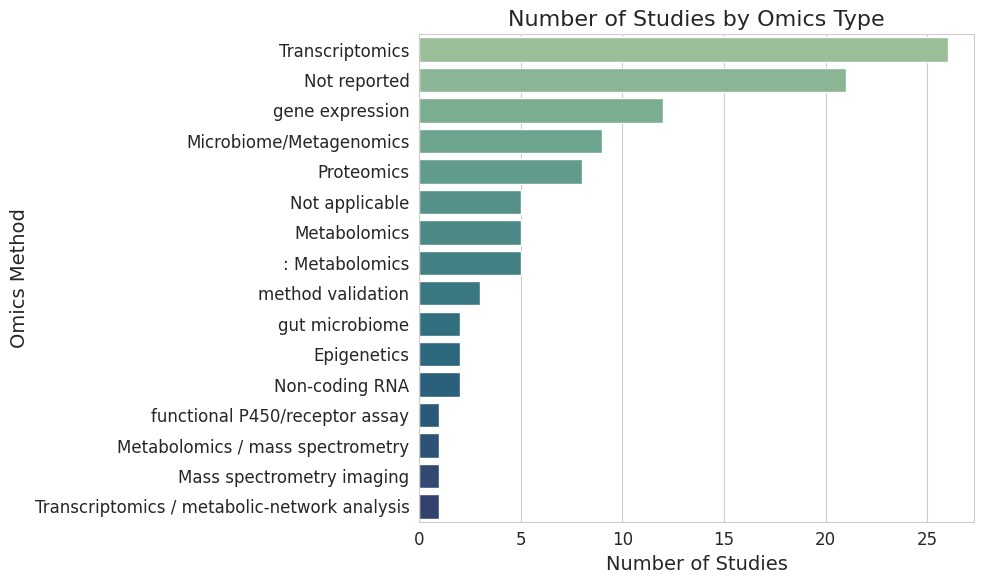

✅ Chart saved as 'Omics_Bar_Chart.png'

📊 Omics distribution:
                                       Omics  Count
                             Transcriptomics     26
                                Not reported     21
                             gene expression     12
                     Microbiome/Metagenomics      9
                                  Proteomics      8
                              Not applicable      5
                                Metabolomics      5
                              : Metabolomics      5
                           method validation      3
                              gut microbiome      2
                                 Epigenetics      2
                              Non-coding RNA      2
              functional P450/receptor assay      1
            Metabolomics / mass spectrometry      1
                   Mass spectrometry imaging      1
Transcriptomics / metabolic-network analysis      1


In [12]:
# -*- coding: utf-8 -*-
"""
Bee RT‑qPCR – Omics Type Bar Chart
Extracts omics from the 'Omics' column, counts frequencies, and plots a bar graph.
"""

import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# Load your Excel file
FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx'  # adjust if needed

try:
    df = pd.read_excel(FILE_PATH, sheet_name='Data_Extraction')
    print(f"✅ Loaded {len(df)} rows.")
except FileNotFoundError:
    print("❌ File not found. Please upload the file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        df = pd.read_excel(FILE_PATH, sheet_name='Data_Extraction')
        print(f"✅ Loaded {len(df)} rows from {FILE_PATH}.")
    else:
        raise SystemExit("No file uploaded.")

# Clean column names
df.columns = df.columns.str.strip()

# Extract omics entries (split by '+' or ';')
omics_series = df['Omics'].dropna().astype(str)
all_omics = []
for entry in omics_series:
    # Split by '+' or ';' and clean
    parts = re.split(r'[+;]', entry)
    for p in parts:
        p = p.strip()
        if p:
            # Further clean: remove 'Targeted' or 'Multiomics:' prefixes for cleaner labels
            p = re.sub(r'^(RT-qPCR|Multiomics|Targeted)\s*', '', p, flags=re.IGNORECASE)
            p = re.sub(r'\(.*\)', '', p).strip()  # remove parentheses content
            if p:
                all_omics.append(p)

# Count and sort
omics_counts = Counter(all_omics)
omics_df = pd.DataFrame(omics_counts.items(), columns=['Omics', 'Count'])
omics_df = omics_df.sort_values('Count', ascending=False)

# Plot
plt.figure(figsize=(10, 6))
sns.barplot(data=omics_df, x='Count', y='Omics', palette='crest')
plt.title('Number of Studies by Omics Type', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.ylabel('Omics Method', fontsize=14)
plt.tight_layout()
plt.savefig('Omics_Bar_Chart.png', dpi=300)
plt.show()

print("✅ Chart saved as 'Omics_Bar_Chart.png'")
print("\n📊 Omics distribution:")
print(omics_df.to_string(index=False))

In [13]:
# -*- coding: utf-8 -*-
"""
Bee Omics Dataset – Country & Omics Bar Charts
Extracts countries and omics types from the Excel file and plots two bar graphs.
"""

import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# ============================================================================
# 1. Load the file (adjust file name if needed)
# ============================================================================
FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_Omics.xlsx'  # your omics file

try:
    df = pd.read_excel(FILE_PATH, sheet_name='Completed Extraction')
    print(f"✅ Loaded {len(df)} rows from sheet 'Completed Extraction'.")
except FileNotFoundError:
    print("❌ File not found. Please upload the file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        # Try common sheet names
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            target_sheet = sheet_names[0]
            print(f"Using first sheet: {target_sheet}")
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise SystemExit("No file uploaded.")

# Clean column names
df.columns = df.columns.str.strip()

# ============================================================================
# 2. Extract countries (split multiple entries)
# ============================================================================
country_series = df['Country'].dropna().astype(str)
all_countries = []
for entry in country_series:
    # split by semicolon, comma, or ';'
    parts = re.split(r'[;, ]+', entry)
    for p in parts:
        p = p.strip()
        if p and len(p) > 1:
            all_countries.append(p)

country_counts = Counter(all_countries)
country_df = pd.DataFrame(country_counts.items(), columns=['Country', 'Count'])
country_df = country_df.sort_values('Count', ascending=False)

# ============================================================================
# 3. Extract omics types (split multiple)
# ============================================================================
omics_series = df['Omics'].dropna().astype(str)
all_omics = []
for entry in omics_series:
    # split by '+' or ';'
    parts = re.split(r'[+;]', entry)
    for p in parts:
        p = p.strip()
        if p:
            # Remove extra descriptors like "(Targeted)" for cleaner labels
            p = re.sub(r'\(.*\)', '', p).strip()
            # Handle "Multiomics: Metabolomics + microbiome" -> extract individual
            if ':' in p:
                # take after colon
                p = p.split(':', 1)[1].strip()
            # If there are still spaces, split further (e.g., "Transcriptomics + Metabolomics")
            subparts = re.split(r'[+;]', p)
            for sp in subparts:
                sp = sp.strip()
                if sp:
                    all_omics.append(sp)

omics_counts = Counter(all_omics)
omics_df = pd.DataFrame(omics_counts.items(), columns=['Omics', 'Count'])
omics_df = omics_df.sort_values('Count', ascending=False)

# ============================================================================
# 4. Plot Country Bar Chart
# ============================================================================
plt.figure(figsize=(12, 8))
sns.barplot(data=country_df.head(15), x='Count', y='Country', palette='Reds_r')
plt.title('Number of Omics Studies by Country', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.ylabel('Country', fontsize=14)
plt.tight_layout()
plt.savefig('Omics_Country_Bar_Chart.png', dpi=300)
plt.show()

print("✅ Country chart saved as 'Omics_Country_Bar_Chart.png'")

# ============================================================================
# 5. Plot Omics Type Bar Chart
# ============================================================================
plt.figure(figsize=(12, 8))
sns.barplot(data=omics_df.head(15), x='Count', y='Omics', palette='crest')
plt.title('Number of Studies by Omics Type', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.ylabel('Omics Method', fontsize=14)
plt.tight_layout()
plt.savefig('Omics_Type_Bar_Chart.png', dpi=300)
plt.show()

print("✅ Omics chart saved as 'Omics_Type_Bar_Chart.png'")

# ============================================================================
# 6. Print summary tables
# ============================================================================
print("\n📊 Top Countries:")
print(country_df.head(10).to_string(index=False))
print("\n📊 Top Omics Types:")
print(omics_df.head(10).to_string(index=False))

ValueError: Worksheet named 'Completed Extraction' not found

📄 Available sheets: ['Data_Extraction']
✅ Loaded 202 rows from sheet 'Data_Extraction'.


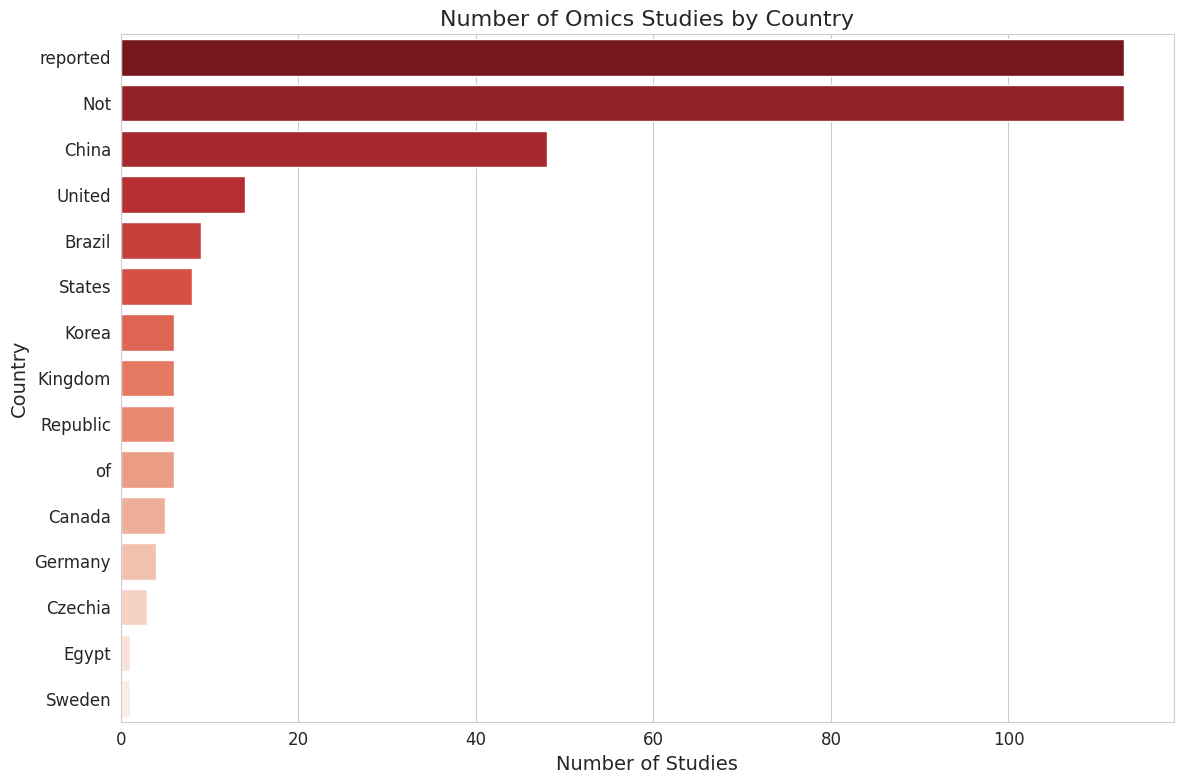

✅ Country chart saved as 'Omics_Country_Bar_Chart.png'


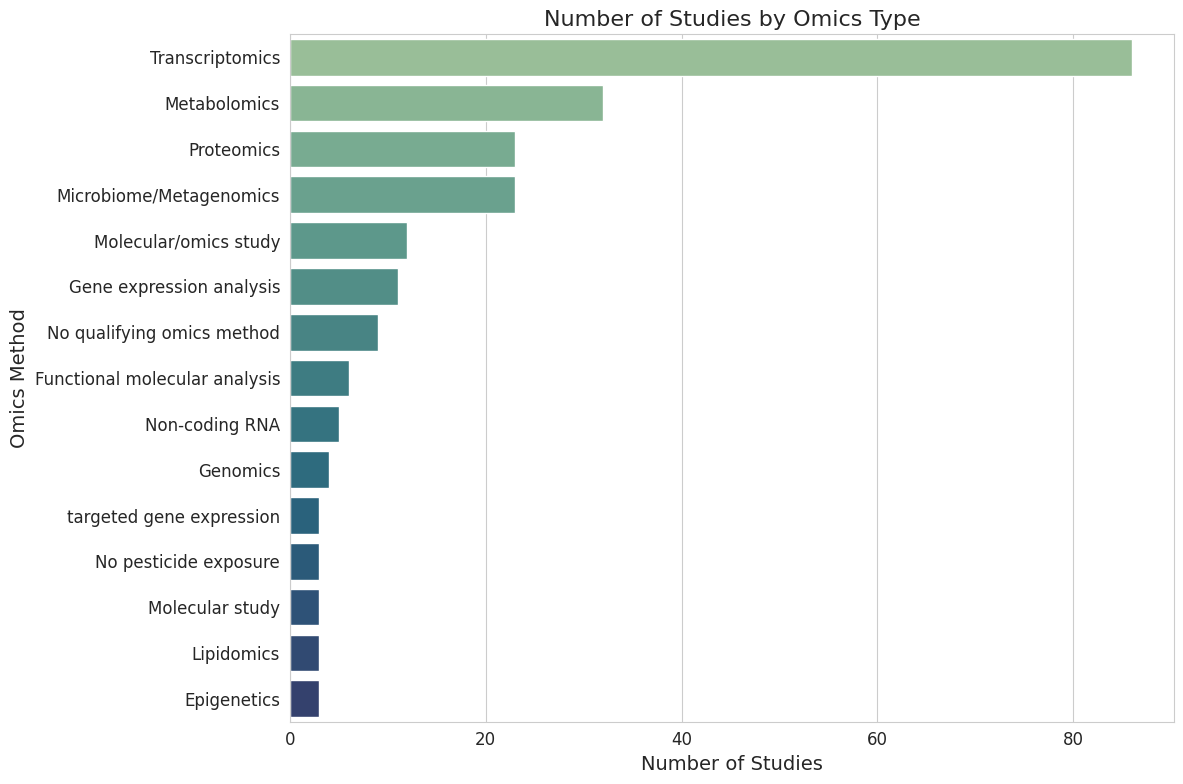

✅ Omics chart saved as 'Omics_Type_Bar_Chart.png'

📊 Top Countries:
 Country  Count
reported    113
     Not    113
   China     48
  United     14
  Brazil      9
  States      8
   Korea      6
 Kingdom      6
Republic      6
      of      6

📊 Top Omics Types:
                        Omics  Count
              Transcriptomics     86
                 Metabolomics     32
                   Proteomics     23
      Microbiome/Metagenomics     23
        Molecular/omics study     12
     Gene expression analysis     11
   No qualifying omics method      9
Functional molecular analysis      6
               Non-coding RNA      5
                     Genomics      4


In [14]:
# -*- coding: utf-8 -*-
"""
Bee Omics Dataset – Country & Omics Bar Charts
Extracts countries and omics types from the Excel file and plots two bar graphs.
Robust sheet detection – works with any sheet name.
"""

import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter

# ============================================================================
# 1. Load the file with automatic sheet detection
# ============================================================================
FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_Omics.xlsx'  # your omics file
df = None

try:
    # First try the common sheet name
    df = pd.read_excel(FILE_PATH, sheet_name='Completed Extraction')
    print(f"✅ Loaded {len(df)} rows from sheet 'Completed Extraction'.")
except FileNotFoundError:
    print("❌ File not found locally. Please upload the Excel file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        print(f"✅ Uploaded file: {FILE_PATH}")
        # List all sheets
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        # Try common names
        for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1', 'Data_Extraction']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            print("Could not find a default sheet. Please type the exact sheet name from the list above:")
            target_sheet = input().strip()
            if target_sheet not in sheet_names:
                print(f"❌ Sheet '{target_sheet}' not found. Using first sheet: {sheet_names[0]}")
                target_sheet = sheet_names[0]
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise SystemExit("No file uploaded.")
except ValueError as e:
    # If sheet name not found but file exists
    if 'Worksheet named' in str(e):
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1', 'Data_Extraction']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            print("Could not find a default sheet. Please type the exact sheet name from the list above:")
            target_sheet = input().strip()
            if target_sheet not in sheet_names:
                print(f"❌ Sheet '{target_sheet}' not found. Using first sheet: {sheet_names[0]}")
                target_sheet = sheet_names[0]
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise

# Clean column names
df.columns = df.columns.str.strip()

# ============================================================================
# 2. Extract countries (split multiple entries)
# ============================================================================
country_series = df['Country'].dropna().astype(str)
all_countries = []
for entry in country_series:
    parts = re.split(r'[;, ]+', entry)
    for p in parts:
        p = p.strip()
        if p and len(p) > 1:
            all_countries.append(p)

country_counts = Counter(all_countries)
country_df = pd.DataFrame(country_counts.items(), columns=['Country', 'Count'])
country_df = country_df.sort_values('Count', ascending=False)

# ============================================================================
# 3. Extract omics types (split multiple)
# ============================================================================
omics_series = df['Omics'].dropna().astype(str)
all_omics = []
for entry in omics_series:
    # split by '+' or ';'
    parts = re.split(r'[+;]', entry)
    for p in parts:
        p = p.strip()
        if p:
            # Remove extra descriptors
            p = re.sub(r'\(.*\)', '', p).strip()
            # Handle "Multiomics: Metabolomics + microbiome" -> extract individual
            if ':' in p:
                p = p.split(':', 1)[1].strip()
            # Further split if there are still spaces
            subparts = re.split(r'[+;]', p)
            for sp in subparts:
                sp = sp.strip()
                if sp:
                    all_omics.append(sp)

omics_counts = Counter(all_omics)
omics_df = pd.DataFrame(omics_counts.items(), columns=['Omics', 'Count'])
omics_df = omics_df.sort_values('Count', ascending=False)

# ============================================================================
# 4. Plot Country Bar Chart
# ============================================================================
plt.figure(figsize=(12, 8))
sns.barplot(data=country_df.head(15), x='Count', y='Country', palette='Reds_r')
plt.title('Number of Omics Studies by Country', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.ylabel('Country', fontsize=14)
plt.tight_layout()
plt.savefig('Omics_Country_Bar_Chart.png', dpi=300)
plt.show()
print("✅ Country chart saved as 'Omics_Country_Bar_Chart.png'")

# ============================================================================
# 5. Plot Omics Type Bar Chart
# ============================================================================
plt.figure(figsize=(12, 8))
sns.barplot(data=omics_df.head(15), x='Count', y='Omics', palette='crest')
plt.title('Number of Studies by Omics Type', fontsize=16)
plt.xlabel('Number of Studies', fontsize=14)
plt.ylabel('Omics Method', fontsize=14)
plt.tight_layout()
plt.savefig('Omics_Type_Bar_Chart.png', dpi=300)
plt.show()
print("✅ Omics chart saved as 'Omics_Type_Bar_Chart.png'")

# ============================================================================
# 6. Print summary tables
# ============================================================================
print("\n📊 Top Countries:")
print(country_df.head(10).to_string(index=False))
print("\n📊 Top Omics Types:")
print(omics_df.head(10).to_string(index=False))

In [15]:
# -*- coding: utf-8 -*-
"""
Bee Omics – Gene Filtering & Interpretation
Loads only the omics Excel file, filters studies that mention specified genes,
and generates cross‑tabulations with pesticides and species.
"""

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print("="*60)
print("🐝 BEE OMICS – GENE FILTER & INTERPRETATION")
print("="*60)

# ============================================================================
# 1. LOAD OMICS DATA (with sheet detection)
# ============================================================================

FILE_PATH = 'Bee_Toxicogenomics_Data_Extraction_Omics.xlsx'
df = None

try:
    # Try common sheet names
    xl = pd.ExcelFile(FILE_PATH)
    sheet_names = xl.sheet_names
    print(f"📄 Available sheets: {sheet_names}")
    target_sheet = None
    for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1']:
        if candidate in sheet_names:
            target_sheet = candidate
            break
    if target_sheet is None:
        print("Could not find a default sheet. Using the first one.")
        target_sheet = sheet_names[0]
    df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
    print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
except FileNotFoundError:
    print("❌ File not found. Please upload the omics Excel file.")
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        FILE_PATH = list(uploaded.keys())[0]
        xl = pd.ExcelFile(FILE_PATH)
        sheet_names = xl.sheet_names
        print(f"📄 Available sheets: {sheet_names}")
        target_sheet = None
        for candidate in ['Completed Extraction', 'Extraction', 'Data', 'Sheet1']:
            if candidate in sheet_names:
                target_sheet = candidate
                break
        if target_sheet is None:
            target_sheet = sheet_names[0]
        df = pd.read_excel(FILE_PATH, sheet_name=target_sheet)
        print(f"✅ Loaded {len(df)} rows from sheet '{target_sheet}'.")
    else:
        raise SystemExit("No file uploaded.")

# Clean column names
df.columns = df.columns.str.strip()

# Ensure 'Key DEGs' column exists
if 'Key DEGs' not in df.columns:
    print("⚠️ 'Key DEGs' column not found. Creating empty column.")
    df['Key DEGs'] = np.nan

# ============================================================================
# 2. FILTER OUT ROWS WITH NO GENE REPORTED
# ============================================================================

# Convert to string and lower case for searching
df['Key_DEGs_str'] = df['Key DEGs'].astype(str).str.lower()
# Keep only rows where Key DEGs is not empty, not "nan", not "not reported"
mask_not_empty = (df['Key_DEGs_str'].notna()) & (df['Key_DEGs_str'] != '') & (df['Key_DEGs_str'] != 'nan') & (df['Key_DEGs_str'] != 'not reported')
df_reported = df[mask_not_empty].copy()
print(f"📊 Total studies with reported genes: {len(df_reported)}")

if len(df_reported) == 0:
    print("❌ No studies with gene lists found. Exiting.")
    raise SystemExit("No data.")

# ============================================================================
# 3. USER INPUT: Gene list to search
# ============================================================================

print("\nEnter the genes or gene families you want to search for.")
print("Separate multiple entries with semicolons (;).")
print("Example: SFCYP1; CYP6BE1; P450s; UGTs; AChE2; Def-1; Histone H2A.V")
print("Leave empty to see all studies with reported genes (no filtering).")

gene_input = input("\n👉 Enter gene list (or press Enter to skip): ").strip()

if gene_input:
    # Split by semicolon, comma, or newline
    genes_to_find = re.split(r'[;,]+', gene_input)
    genes_to_find = [g.strip() for g in genes_to_find if g.strip()]
    print(f"🔎 Searching for {len(genes_to_find)} gene terms: {genes_to_find}")
else:
    genes_to_find = []
    print("🔎 No gene list provided – will show all studies with reported genes.")

# ============================================================================
# 4. SEARCH FOR GENES
# ============================================================================

if genes_to_find:
    # Create a regex pattern that matches any of the gene terms (case‑insensitive)
    pattern = '|'.join(re.escape(g) for g in genes_to_find)
    mask_match = df_reported['Key_DEGs_str'].str.contains(pattern, na=False)
    df_matched = df_reported[mask_match].copy()
    print(f"✅ Found {len(df_matched)} studies that mention at least one of your genes.")
else:
    df_matched = df_reported.copy()
    print(f"✅ Keeping all {len(df_matched)} studies with reported genes.")

if len(df_matched) == 0:
    print("❌ No matches found. Exiting.")
    raise SystemExit("No matching studies.")

# ============================================================================
# 5. EXTRACT MATCHING GENES FOR EACH STUDY
# ============================================================================

def extract_matching_genes(row, gene_list):
    """Return list of genes from the user's list that appear in Key DEGs of this row."""
    text = str(row['Key DEGs']).lower()
    matches = []
    for g in gene_list:
        if g.lower() in text:
            matches.append(g)
    return matches

if genes_to_find:
    df_matched['Matched_genes'] = df_matched.apply(lambda row: extract_matching_genes(row, genes_to_find), axis=1)
else:
    # If no gene list, we can still extract all genes mentioned (but that's huge)
    # We'll skip or put a placeholder.
    df_matched['Matched_genes'] = df_matched['Key DEGs'].apply(lambda x: [str(x)])

# ============================================================================
# 6. SUMMARY TABLES AND CROSS‑TABULATIONS
# ============================================================================

print("\n" + "="*60)
print("📊 SUMMARY OF MATCHING STUDIES")
print("="*60)

# Show sample of key columns
cols_to_show = ['DOI', 'Author', 'Year', 'Pesticide', 'Pesticide class', 'Bee species', 'Tissue', 'Key DEGs']
existing_cols = [c for c in cols_to_show if c in df_matched.columns]
print("\n🔍 Sample of matching studies (first 5 rows):")
print(df_matched[existing_cols].head(5).to_string(index=False))

# === CROSS‑TABULATIONS ===
if genes_to_find:
    # Explode the Matched_genes list to create a row per gene per study
    gene_presence = df_matched[['Matched_genes', 'Pesticide', 'Pesticide class', 'Bee species']].copy()
    gene_presence = gene_presence.explode('Matched_genes')
    gene_presence.rename(columns={'Matched_genes': 'Gene'}, inplace=True)
    gene_presence = gene_presence.dropna(subset=['Gene'])

    if not gene_presence.empty:
        # Gene vs Pesticide (specific chemical)
        gene_pest_cross = pd.crosstab(gene_presence['Gene'], gene_presence['Pesticide'])
        # Add row totals
        gene_pest_cross['Total'] = gene_pest_cross.sum(axis=1)
        gene_pest_cross_sorted = gene_pest_cross.sort_values('Total', ascending=False)
        print("\n📊 Gene vs Pesticide (Top 10 genes):")
        print(gene_pest_cross_sorted.head(10).to_string())

        # Gene vs Pesticide class (broader category)
        gene_class_cross = pd.crosstab(gene_presence['Gene'], gene_presence['Pesticide class'])
        gene_class_cross['Total'] = gene_class_cross.sum(axis=1)
        gene_class_cross_sorted = gene_class_cross.sort_values('Total', ascending=False)
        print("\n📊 Gene vs Pesticide Class (Top 10 genes):")
        print(gene_class_cross_sorted.head(10).to_string())

        # Gene vs Species
        gene_species_cross = pd.crosstab(gene_presence['Gene'], gene_presence['Bee species'])
        gene_species_cross['Total'] = gene_species_cross.sum(axis=1)
        gene_species_cross_sorted = gene_species_cross.sort_values('Total', ascending=False)
        print("\n📊 Gene vs Species (Top 10 genes):")
        print(gene_species_cross_sorted.head(10).to_string())

# ============================================================================
# 7. FREQUENCY TABLES
# ============================================================================

# Top genes among matched studies
if genes_to_find:
    all_matched_genes = [g for sublist in df_matched['Matched_genes'] for g in sublist]
    gene_counts = Counter(all_matched_genes)
    top_genes_df = pd.DataFrame(gene_counts.most_common(20), columns=['Gene', 'Frequency'])
    print("\n📊 Top 10 genes in matched studies:")
    print(top_genes_df.head(10).to_string(index=False))

    # Top pesticides
    top_pesticides = df_matched['Pesticide'].value_counts().head(10)
    print("\n📊 Top 10 pesticides in matched studies:")
    print(top_pesticides.to_string())

    # Top species
    top_species = df_matched['Bee species'].value_counts().head(10)
    print("\n📊 Top 10 bee species in matched studies:")
    print(top_species.to_string())

# ============================================================================
# 8. EXPORT RESULTS
# ============================================================================

print("\n📁 Exporting results...")
df_matched.to_csv('Omics_Genes_Matched_Studies.csv', index=False)

if genes_to_find and not gene_presence.empty:
    gene_pest_cross.to_csv('Omics_Gene_vs_Pesticide.csv')
    gene_class_cross.to_csv('Omics_Gene_vs_PesticideClass.csv')
    gene_species_cross.to_csv('Omics_Gene_vs_Species.csv')
    pd.DataFrame(gene_counts.most_common(20), columns=['Gene', 'Frequency']).to_csv('Omics_Top_Genes.csv', index=False)
    top_pesticides.to_csv('Omics_Top_Pesticides_in_Matched.csv')
    top_species.to_csv('Omics_Top_Species_in_Matched.csv')

# Combined Excel workbook
with pd.ExcelWriter('Omics_Gene_Filter_Results.xlsx', engine='openpyxl') as writer:
    df_matched.to_excel(writer, sheet_name='Matched Studies', index=False)
    if genes_to_find and not gene_presence.empty:
        gene_pest_cross.to_excel(writer, sheet_name='Gene_vs_Pesticide')
        gene_class_cross.to_excel(writer, sheet_name='Gene_vs_PesticideClass')
        gene_species_cross.to_excel(writer, sheet_name='Gene_vs_Species')
        pd.DataFrame(gene_counts.most_common(20), columns=['Gene', 'Frequency']).to_excel(writer, sheet_name='Top Genes', index=False)
        top_pesticides.to_excel(writer, sheet_name='Top Pesticides')
        top_species.to_excel(writer, sheet_name='Top Species')
print("✅ Exported all results.")

# ============================================================================
# 9. INTERPRETATION SUMMARY
# ============================================================================

print("\n" + "="*60)
print("🔍 INTERPRETATION SUMMARY")
print("="*60)

if genes_to_find:
    print(f"• Found {len(df_matched)} omics studies that mention at least one of your specified genes.")
    print(f"• The most frequently mentioned genes are:")
    for gene, freq in gene_counts.most_common(5):
        print(f"    - {gene}: {freq} studies")
    print(f"\n• The most studied pesticides among these gene‑focused studies are:")
    for pest, count in top_pesticides.head(5).items():
        print(f"    - {pest}: {count} studies")
    print(f"\n• The most studied species are:")
    for sp, count in top_species.head(5).items():
        print(f"    - {sp}: {count} studies")
else:
    print("No gene list provided – you have all omics studies with reported genes.")
    print("Use the exported files to manually explore which genes appear.")

print("\n💡 Open 'Omics_Gene_Filter_Results.xlsx' to explore the cross‑tabulations.")
print("   The 'Gene_vs_Pesticide' sheet shows which pesticides are associated with each gene.")
print("   The 'Gene_vs_Species' sheet shows which species are associated with each gene.")
print("   This helps interpret the chemical and biological context of your genes of interest.")

# ============================================================================
# 10. OPTIONAL: BAR CHART OF TOP GENES
# ============================================================================

if genes_to_find and not top_genes_df.empty:
    plt.figure(figsize=(12, 8))
    top10 = top_genes_df.head(10)
    sns.barplot(data=top10, x='Frequency', y='Gene', palette='viridis')
    plt.title('Top 10 Genes in Matched Omics Studies', fontsize=16)
    plt.xlabel('Number of Studies', fontsize=14)
    plt.tight_layout()
    plt.savefig('Omics_Top_Genes_BarChart.png', dpi=300)
    plt.show()
    print("✅ Bar chart saved as 'Omics_Top_Genes_BarChart.png'")

print("\n🎉 Done!")

🐝 BEE OMICS – GENE FILTER & INTERPRETATION
📄 Available sheets: ['Data_Extraction']
Could not find a default sheet. Using the first one.
✅ Loaded 202 rows from sheet 'Data_Extraction'.
📊 Total studies with reported genes: 62

Enter the genes or gene families you want to search for.
Separate multiple entries with semicolons (;).
Example: SFCYP1; CYP6BE1; P450s; UGTs; AChE2; Def-1; Histone H2A.V
Leave empty to see all studies with reported genes (no filtering).

👉 Enter gene list (or press Enter to skip): 
🔎 No gene list provided – will show all studies with reported genes.
✅ Keeping all 62 studies with reported genes.

📊 SUMMARY OF MATCHING STUDIES

🔍 Sample of matching studies (first 5 rows):
                          DOI                Author  Year                 Pesticide         Pesticide class              Bee species                   Tissue                                                                                   Key DEGs
   10.1186/s12864-025-12435-7       El-wahab et al

In [16]:
# =============================================================================
# OMICS-ONLY GENE PRESENCE ANALYSIS – TABLES & FIGURES
# =============================================================================
# This script is designed for the omics.xlsx file (global omics studies only).
# It extracts all reported genes, builds presence matrices, generates
# frequency tables per pesticide class and species, and produces heatmaps.
# =============================================================================

# 1. Setup
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files as colab_files
from openpyxl import load_workbook
from openpyxl.styles import PatternFill, Color
from openpyxl.formatting.rule import ColorScaleRule

# 2. Upload the file (omics.xlsx or v2)
print("Please upload your file (omics.xlsx or Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx)")
uploaded = colab_files.upload()
filename = list(uploaded.keys())[0]
print(f"Loaded: {filename}")

# 3. Load the data
sheets = pd.read_excel(filename, sheet_name=None)
df = None
for sheet_name in ['Completed Extraction v2', 'Completed Extraction', 'Sheet1']:
    if sheet_name in sheets:
        df = sheets[sheet_name]
        break
if df is None:
    df = list(sheets.values())[0]
print(f"Loaded data: {df.shape[0]} rows, {df.shape[1]} columns")

# 4. Create Study_type column if missing
if 'Study type' not in df.columns:
    global_terms = ['transcriptom', 'proteom', 'metabolom', 'epigenet', 'lipidom',
                    'multi-omics', 'mass spectrometry', 'omics']
    def classify(row):
        omics = str(row.get('Omics', '')).lower()
        if any(term in omics for term in global_terms):
            return 'Type A: Global Omics'
        elif 'rt-qpcr' in omics or 'qpcr' in omics or 'targeted' in omics:
            return 'Type B: Targeted RT-qPCR'
        else:
            return 'Other'
    df['Study_type'] = df.apply(classify, axis=1)

# 5. If this is the full v2 file, filter to only omics studies (Type A)
# If you upload omics.xlsx, all rows are already omics, so this step will keep everything.
if len(df[df['Study_type'] == 'Type A: Global Omics']) > 0:
    df = df[df['Study_type'] == 'Type A: Global Omics'].copy()
    print(f"Filtered to {len(df)} global omics studies.")
else:
    print("No 'Type A: Global Omics' found. Using all rows.")

# 6. Filter out non-eligible rows based on Status
if 'Status' in df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded']
    eligible = ~df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    df = df[eligible].copy()
    print(f"After Status filter: {len(df)} rows remain.")

# 7. Extract genes from Key DEGs
def extract_genes(deg_col):
    if pd.isna(deg_col):
        return []
    # Remove System: tags
    cleaned = re.sub(r'\(System:[^)]+\)', '', str(deg_col))
    # Split by common delimiters
    genes = re.split(r'[;,/]\s*', cleaned)
    result = []
    for g in genes:
        g = g.strip()
        if g and not g.startswith('Not') and not g.startswith('Targeted'):
            g = re.sub(r'^[\d\s]+', '', g)  # remove leading digits
            if g and len(g) > 1:
                result.append(g)
    return result

df['Gene_list'] = df['Key DEGs'].apply(extract_genes)

# 8. Build gene presence matrix (only genes appearing in >= 2 studies)
all_genes_flat = [g for sublist in df['Gene_list'] for g in sublist]
gene_counts = Counter(all_genes_flat)
frequent_genes = [g for g, c in gene_counts.items() if c >= 2]
print(f"Found {len(frequent_genes)} genes reported in at least 2 omics studies.")

# Create presence matrix
presence_df = pd.DataFrame(0, index=df.index, columns=frequent_genes)
for idx, genes in zip(df.index, df['Gene_list']):
    for g in genes:
        if g in frequent_genes:
            presence_df.loc[idx, g] = 1

# Add metadata
presence_df['Pesticide_class'] = df['Pesticide class'].values
presence_df['Pesticide'] = df['Pesticide'].values
presence_df['Species'] = df['Bee species'].values
presence_df['Study_id'] = df.index

# 9. Compute frequencies per group
def compute_freq(data, group_col):
    results = {}
    for group in data[group_col].dropna().unique():
        if pd.isna(group) or group == '':
            continue
        mask = data[group_col] == group
        n = mask.sum()
        if n == 0:
            continue
        sub = data[mask][frequent_genes]
        freq = sub.sum(axis=0) / n
        results[group] = freq.sort_values(ascending=False)
    return results

class_freq = compute_freq(presence_df, 'Pesticide_class')
species_freq = compute_freq(presence_df, 'Species')
pesticide_freq = compute_freq(presence_df, 'Pesticide')

# 10. Define genes of interest (from your earlier list)
genes_of_interest = [
    'SFCYP1', 'SFCYP2', 'SFCYP3', 'SFCYP4', 'SFCYP5', 'SFRYR',
    'Def-1', 'HYM', 'API', 'cpr14', 'ABA', 'LYS',
    'Histone H2A.V', 'CYP6BE1', 'CYP6AQ1',
    'AChE2', 'VGlut', 'GluRIB',
    'CYP6AQ26', 'CYP6AQ27', 'CYP6AQ28',
    'EDD1', 'PI3K', 'Ptc', 'FoxO', 'Jra', 'Argk',
    'LOC107999471', 'Anpepl1', 'GGTLC1', 'AmDld',
    'CYP6AQ1', 'Obp6', 'Kakusei', 'Myosin-7', 'Titin', 'Hymenoptaecin',
    'Aldh', 'myosin-IIIb', 'inaE', 'trpl', 'Trpgamma', 'CaMKII',
    'Flightin', 'Ac3', 'A4', 'ACSF2', 'Cryl1', 'Apid1', 'Blop',
    'LOC100577632', 'Esterase-4', 'CYP9Q2', 'CYP9Q3',
    'abaecin', 'cyp9e2', 'cyp302a1', 'GstD1',
    'MRJP1', 'SLC25A10', 'PHKB', 'MYH9', 'FASN', 'MVK',
    'GluRA', 'Nmdar1', 'Tyr1', 'Transferrin 1',
    'OBP21', 'GST', 'NST-1', 'ame-miR-283-5p', 'AmALKBH1', 'OBP17'
]
# Keep only those present in the dataset
genes_of_interest = [g for g in genes_of_interest if g in frequent_genes]
print(f"Found {len(genes_of_interest)} of your listed genes in the dataset.")

# 11. Build focused tables
# Class frequency table
class_table = pd.DataFrame(index=genes_of_interest)
for cls, freq_series in class_freq.items():
    class_table[cls] = [freq_series.get(g, 0) for g in genes_of_interest]

# Species frequency table (top 10 species)
top_species = list(species_freq.keys())[:10]
species_table = pd.DataFrame(index=genes_of_interest)
for sp in top_species:
    species_table[sp] = [species_freq[sp].get(g, 0) for g in genes_of_interest]

# Overall gene frequency
overall_freq = pd.Series(gene_counts).sort_values(ascending=False)
overall_df = overall_freq.head(50).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'})
overall_df['Proportion'] = overall_df['Frequency'] / len(df)

# 12. Create output directory
os.makedirs('outputs', exist_ok=True)

# 13. Save tables to Excel (with conditional formatting)
output_xlsx = 'outputs/omics_gene_presence_tables.xlsx'

with pd.ExcelWriter(output_xlsx, engine='openpyxl') as writer:
    # Sheet 1: Overall gene frequency
    overall_df.to_excel(writer, sheet_name='Overall Frequency', index=False)

    # Sheet 2: Class frequency (selected genes)
    class_table.to_excel(writer, sheet_name='Class_Frequency_Selected')

    # Sheet 3: Species frequency (selected genes)
    species_table.to_excel(writer, sheet_name='Species_Frequency_Selected')

    # Sheet 4: Full class frequency (top 30 genes per class)
    for cls, freq_series in list(class_freq.items())[:10]:
        sheet_name = re.sub(r'[\\/*?:\[\]]', '_', str(cls))[:31]
        freq_series.head(30).to_frame('Frequency').reset_index().rename(
            columns={'index': 'Gene'}).to_excel(writer, sheet_name=sheet_name, index=False)

# Apply conditional formatting to the Excel file
wb = load_workbook(output_xlsx)
for sheet_name in wb.sheetnames:
    ws = wb[sheet_name]
    # Find the data range (skip header row)
    if ws.max_row > 1 and ws.max_column > 1:
        # Apply color scale to numeric columns (from column B onwards)
        for col_idx in range(2, ws.max_column + 1):
            col_letter = ws.cell(row=1, column=col_idx).column_letter
            # Skip if column header contains text
            header = ws.cell(row=1, column=col_idx).value
            if header and isinstance(header, str) and 'Gene' in header:
                continue
            # Apply color scale
            cell_range = f"{col_letter}2:{col_letter}{ws.max_row}"
            rule = ColorScaleRule(start_type='min', start_color='FFFFFF',
                                  mid_type='percentile', mid_value=50, mid_color='FFFF00',
                                  end_type='max', end_color='FF0000')
            ws.conditional_formatting.add(cell_range, rule)
wb.save(output_xlsx)
print(f"Excel file saved: {output_xlsx}")

# 14. Generate publication-ready figures
# Figure 1: Heatmap – Selected genes across pesticide classes
if class_table.shape[1] > 1 and class_table.shape[0] > 1:
    plt.figure(figsize=(12, max(6, len(class_table)*0.4)))
    sns.heatmap(class_table, annot=True, cmap='Blues', fmt='.2f',
                cbar_kws={'label': 'Frequency (proportion)'},
                linewidths=0.5, linecolor='white')
    plt.title('Frequency of Selected Genes Across Pesticide Classes', fontsize=14)
    plt.xlabel('Pesticide Class', fontsize=12)
    plt.ylabel('Gene', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('outputs/fig1_heatmap_genes_by_class.png', dpi=300, bbox_inches='tight')
    plt.close()

# Figure 2: Heatmap – Selected genes across species (top 10)
if species_table.shape[1] > 1 and species_table.shape[0] > 1:
    plt.figure(figsize=(12, max(6, len(species_table)*0.4)))
    sns.heatmap(species_table, annot=True, cmap='Greens', fmt='.2f',
                cbar_kws={'label': 'Frequency (proportion)'},
                linewidths=0.5, linecolor='white')
    plt.title('Frequency of Selected Genes Across Bee Species', fontsize=14)
    plt.xlabel('Species', fontsize=12)
    plt.ylabel('Gene', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('outputs/fig2_heatmap_genes_by_species.png', dpi=300, bbox_inches='tight')
    plt.close()

# Figure 3: Top 20 overall genes
top20 = overall_freq.head(20)
plt.figure(figsize=(12, 8))
bars = plt.barh(top20.index, top20.values, color='steelblue')
plt.xlabel('Number of Studies Reporting Gene', fontsize=12)
plt.ylabel('Gene', fontsize=12)
plt.title('Top 20 Most Frequently Reported Genes in Omics Studies', fontsize=14)
plt.gca().invert_yaxis()
for bar, val in zip(bars, top20.values):
    plt.text(val + 0.5, bar.get_y() + bar.get_height()/2, str(val), va='center', fontsize=9)
plt.tight_layout()
plt.savefig('outputs/fig3_top20_genes_bar.png', dpi=300, bbox_inches='tight')
plt.close()

# Figure 4: Count of unique genes per pesticide class
class_gene_counts = {cls: len(freq_series[freq_series > 0]) for cls, freq_series in class_freq.items()}
class_gene_df = pd.DataFrame(class_gene_counts.items(), columns=['Pesticide Class', 'Number of Genes'])
class_gene_df = class_gene_df.sort_values('Number of Genes', ascending=False)
plt.figure(figsize=(12, 6))
sns.barplot(data=class_gene_df, x='Pesticide Class', y='Number of Genes', palette='viridis')
plt.title('Number of Unique Genes Reported per Pesticide Class', fontsize=14)
plt.xlabel('Pesticide Class', fontsize=12)
plt.ylabel('Number of Unique Genes', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/fig4_genes_per_class.png', dpi=300, bbox_inches='tight')
plt.close()

# Figure 5: Gene overlap across classes – UpSet style (simplified as heatmap of shared genes)
# Matrix showing which genes appear in which classes (binary)
class_presence_matrix = pd.DataFrame(0, index=list(class_freq.keys()), columns=frequent_genes)
for cls, freq_series in class_freq.items():
    for gene in freq_series[freq_series > 0].index:
        if gene in frequent_genes:
            class_presence_matrix.loc[cls, gene] = 1

# Filter to genes that appear in at least 2 classes
multi_class_genes = [g for g in frequent_genes if class_presence_matrix[g].sum() >= 2]
if len(multi_class_genes) >= 5:
    class_presence_sub = class_presence_matrix[multi_class_genes[:30]]
    plt.figure(figsize=(14, max(6, len(class_presence_sub)*0.5)))
    sns.heatmap(class_presence_sub, annot=False, cmap='Blues', cbar_kws={'label': 'Gene present (1)'},
                linewidths=0.2, linecolor='gray')
    plt.title('Gene Presence Across Pesticide Classes (Genes Shared by ≥2 Classes)', fontsize=14)
    plt.xlabel('Gene', fontsize=12)
    plt.ylabel('Pesticide Class', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.savefig('outputs/fig5_shared_genes_across_classes.png', dpi=300, bbox_inches='tight')
    plt.close()

# 15. Also create a focused table for your specific genes (SFCYP1-5, etc.)
specific_genes = ['SFCYP1', 'SFCYP2', 'SFCYP3', 'SFCYP4', 'SFCYP5', 'SFRYR', 'Def-1', 'HYM', 'API', 'cpr14', 'ABA', 'LYS']
specific_genes = [g for g in specific_genes if g in frequent_genes]
if len(specific_genes) > 0:
    specific_freq = pd.DataFrame(index=specific_genes)
    for cls, freq_series in class_freq.items():
        specific_freq[cls] = [freq_series.get(g, 0) for g in specific_genes]
    specific_freq.to_excel('outputs/specific_genes_table.xlsx')

    # Bar chart for these genes
    plt.figure(figsize=(12, 6))
    specific_freq.T.plot(kind='bar')
    plt.title('Frequency of Egyptian Honey Bee Genes Across Pesticide Classes', fontsize=14)
    plt.xlabel('Pesticide Class', fontsize=12)
    plt.ylabel('Frequency (proportion)', fontsize=12)
    plt.xticks(rotation=45, ha='right')
    plt.legend(title='Gene', bbox_to_anchor=(1.05, 1))
    plt.tight_layout()
    plt.savefig('outputs/fig6_egyptian_genes_freq.png', dpi=300, bbox_inches='tight')
    plt.close()

# 16. Create a summary statistics table
summary_data = {
    'Metric': [
        'Total omics studies analyzed',
        'Total unique genes reported',
        'Genes reported in ≥2 studies',
        'Number of pesticide classes',
        'Number of species',
        'Top gene reported',
        'Top gene frequency'
    ],
    'Value': [
        len(df),
        len(gene_counts),
        len(frequent_genes),
        len(class_freq),
        len(species_freq),
        overall_freq.index[0] if len(overall_freq) > 0 else 'N/A',
        overall_freq.iloc[0] if len(overall_freq) > 0 else 'N/A'
    ]
}
summary_df = pd.DataFrame(summary_data)
summary_df.to_excel('outputs/summary_statistics.xlsx', index=False)

# 17. Zip and download
zip_path = 'omics_gene_presence_results.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\n" + "="*60)
print("ANALYSIS COMPLETE! Summary:")
print(f"  - Omics studies analyzed: {len(df)}")
print(f"  - Total unique genes: {len(gene_counts)}")
print(f"  - Genes in ≥2 studies: {len(frequent_genes)}")
print(f"  - Pesticide classes: {len(class_freq)}")
print(f"  - Species: {len(species_freq)}")
print("="*60)

# Print top 10 genes
print("\nTop 10 Most Frequently Reported Genes:")
for gene, count in overall_freq.head(10).items():
    print(f"  {gene}: {count} studies ({count/len(df)*100:.1f}%)")

# Download
try:
    colab_files.download(zip_path)
    print(f"\nDownloaded: {zip_path}")
except:
    print("\nPlease download the zip file manually from the Colab file browser.")

Please upload your file (omics.xlsx or Bee_Toxicogenomics_Data_Extraction_v2_RTqPCR_Completed.xlsx)


Saving Bee_Toxicogenomics_Data_Extraction_Omics.xlsx to Bee_Toxicogenomics_Data_Extraction_Omics (7).xlsx
Loaded: Bee_Toxicogenomics_Data_Extraction_Omics (7).xlsx
Loaded data: 202 rows, 26 columns
Filtered to 177 global omics studies.
After Status filter: 156 rows remain.
Found 13 genes reported in at least 2 omics studies.
Found 5 of your listed genes in the dataset.
Excel file saved: outputs/omics_gene_presence_tables.xlsx

ANALYSIS COMPLETE! Summary:
  - Omics studies analyzed: 156
  - Total unique genes: 162
  - Genes in ≥2 studies: 13
  - Pesticide classes: 52
  - Species: 17

Top 10 Most Frequently Reported Genes:
  UGTs: 4 studies (2.6%)
  GST: 3 studies (1.9%)
  GLS: 2 studies (1.3%)
  GAD: 2 studies (1.3%)
  AChE2: 2 studies (1.3%)
  CYP6AQ1: 2 studies (1.3%)
  ACHE: 2 studies (1.3%)
  stress: 2 studies (1.3%)
  CYP450s: 2 studies (1.3%)
  P450s: 2 studies (1.3%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


Downloaded: omics_gene_presence_results.zip


In [18]:
# =============================================================================
# RT‑qPCR DATA ANALYSIS – BEE TOXICOGENOMICS (Corrected)
# =============================================================================

# 1. Install and import libraries
!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
from google.colab import files

# 2. Upload the file
print("Please upload the file: Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

# 3. Load the data (first sheet)
df = pd.read_excel(filename, sheet_name=0)
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns")

# 4. Filter out non‑eligible rows
if 'Status' in df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded', 'Correction/Erratum']
    eligible = ~df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    df = df[eligible].copy()
    print(f"After filtering by Status, {len(df)} rows remain.")

# 5. Parse the Key DEGs column
def parse_key_degs(deg_text):
    if pd.isna(deg_text):
        return []
    entries = re.split(r'[;,]\s*', str(deg_text))
    parsed = []
    for entry in entries:
        entry = entry.strip()
        if not entry:
            continue
        gene_match = re.match(r'^([^(\s]+)', entry)
        if not gene_match:
            continue
        gene = gene_match.group(1).strip()
        sys_match = re.search(r'System:\s*([^,)]+)', entry)
        system = sys_match.group(1).strip() if sys_match else None
        # Extract fold change
        fold = None
        fold_match = re.search(r'([+-]?\s*\d+\.?\d*)\s*[xX%]', entry)
        if fold_match:
            fold_str = fold_match.group(1).replace('+', '').replace('−', '-').strip()
            try:
                fold = float(fold_str)
                if '%' in entry:
                    fold = fold / 100
            except:
                pass
        direction = 'unknown'
        if 'up' in entry.lower() or ('+' in entry and '-' not in entry):
            direction = 'up'
        elif 'down' in entry.lower() or ('-' in entry and '+' not in entry):
            direction = 'down'
        parsed.append({
            'gene': gene,
            'system': system,
            'fold': fold,
            'direction': direction
        })
    return parsed

df['Parsed_genes'] = df['Key DEGs'].apply(parse_key_degs)

# 6. Flatten gene records
gene_records = []
for idx, row in df.iterrows():
    for g in row['Parsed_genes']:
        gene_records.append({
            'Study_ID': idx,
            'DOI': row.get('DOI', ''),
            'Pesticide': row.get('Pesticide', ''),
            'Pesticide_class': row.get('Pesticide class', ''),   # exact column name
            'Species': row.get('Bee species', ''),               # exact column name
            'Life_stage': row.get('Life stage', ''),             # exact column name
            'Caste': row.get('Caste', ''),
            'Tissue': row.get('Tissue', ''),
            'Gene': g['gene'],
            'System': g['system'],
            'Fold_change': g['fold'],
            'Direction': g['direction'],
            'Main_finding': str(row.get('Main findings', ''))[:200]
        })

gene_df = pd.DataFrame(gene_records)
print(f"Extracted {len(gene_df)} gene entries from {df.shape[0]} studies.")

# 7. Build presence matrix (only genes appearing ≥2 times)
gene_counts = gene_df['Gene'].value_counts()
frequent_genes = gene_counts[gene_counts >= 2].index.tolist()
print(f"Found {len(frequent_genes)} genes appearing in at least 2 studies.")

presence = gene_df[gene_df['Gene'].isin(frequent_genes)]
presence_pivot = presence.pivot_table(index='Study_ID', columns='Gene', aggfunc='size', fill_value=0)
presence_pivot = presence_pivot.clip(upper=1)  # binary

# 8. Add metadata (using the columns already present in gene_df)
# We'll join the metadata from the original df using Study_ID
metadata = df[['Pesticide class', 'Pesticide', 'Bee species', 'Life stage', 'Caste', 'Tissue']].copy()
metadata = metadata.rename(columns={
    'Pesticide class': 'Pesticide_class',
    'Bee species': 'Species',
    'Life stage': 'Life_stage'
})
presence_pivot = presence_pivot.join(metadata)

# 9. Compute frequencies by pesticide class
class_freq = {}
for cls in presence_pivot['Pesticide_class'].dropna().unique():
    if pd.isna(cls) or cls == '':
        continue
    sub = presence_pivot[presence_pivot['Pesticide_class'] == cls]
    n = sub.shape[0]
    if n == 0:
        continue
    freq = sub[frequent_genes].sum(axis=0) / n
    class_freq[cls] = freq.sort_values(ascending=False)

# 10. Compute frequencies by species
species_freq = {}
for sp in presence_pivot['Species'].dropna().unique():
    if pd.isna(sp) or sp == '':
        continue
    sub = presence_pivot[presence_pivot['Species'] == sp]
    n = sub.shape[0]
    if n < 2:
        continue
    freq = sub[frequent_genes].sum(axis=0) / n
    species_freq[sp] = freq.sort_values(ascending=False)

# 11. Compute frequencies by individual pesticide
pesticide_freq = {}
for pest in presence_pivot['Pesticide'].dropna().unique():
    if pd.isna(pest) or pest == '':
        continue
    sub = presence_pivot[presence_pivot['Pesticide'] == pest]
    n = sub.shape[0]
    if n < 2:
        continue
    freq = sub[frequent_genes].sum(axis=0) / n
    pesticide_freq[pest] = freq.sort_values(ascending=False)

# 12. Common genes across classes (threshold 20%)
threshold = 0.2
common_genes = {}
unique_genes = {}
for gene in frequent_genes:
    classes_with_gene = [cls for cls, freq_series in class_freq.items() if freq_series.get(gene, 0) >= threshold]
    if len(classes_with_gene) >= 2:
        common_genes[gene] = classes_with_gene
    elif len(classes_with_gene) == 1:
        unique_genes[gene] = classes_with_gene[0]

# 13. Fold‑change ranking
fold_df = gene_df[gene_df['Fold_change'].notna()].copy()
fold_df['abs_fold'] = np.abs(fold_df['Fold_change'])
top_fold = fold_df.sort_values('abs_fold', ascending=False)

# 14. Create output directory
os.makedirs('outputs', exist_ok=True)

# 15. Save summary tables
with pd.ExcelWriter('outputs/rtqpcr_summary_tables.xlsx', engine='openpyxl') as writer:
    gene_counts.to_frame('Count').to_excel(writer, sheet_name='Overall_Gene_Freq')
    for cls, freq_series in class_freq.items():
        sheet_name = re.sub(r'[\\/*?:\[\]]', '_', str(cls))[:31]
        freq_series.head(20).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'}).to_excel(writer, sheet_name=sheet_name, index=False)
    for sp, freq_series in species_freq.items():
        sheet_name = re.sub(r'[\\/*?:\[\]]', '_', str(sp))[:31]
        freq_series.head(20).to_frame('Frequency').reset_index().rename(columns={'index': 'Gene'}).to_excel(writer, sheet_name=sheet_name, index=False)
    pd.DataFrame({'Gene': list(common_genes.keys()), 'Classes': ['; '.join(v) for v in common_genes.values()]}).to_excel(writer, sheet_name='Common_across_classes', index=False)
    pd.DataFrame({'Gene': list(unique_genes.keys()), 'Class': list(unique_genes.values())}).to_excel(writer, sheet_name='Unique_to_class', index=False)
    top_fold[['Gene', 'Pesticide', 'Species', 'Fold_change', 'Direction']].head(50).to_excel(writer, sheet_name='Top_Fold_Changes', index=False)

# 16. Heatmaps
top20_genes = gene_counts.head(20).index.tolist()
class_matrix = pd.DataFrame(index=class_freq.keys(), columns=top20_genes)
for cls in class_freq.keys():
    for gene in top20_genes:
        class_matrix.loc[cls, gene] = class_freq[cls].get(gene, 0)
class_matrix = class_matrix.fillna(0)

plt.figure(figsize=(14, max(4, len(class_matrix)*0.5)))
sns.heatmap(class_matrix, annot=True, cmap='Blues', fmt='.2f', cbar_kws={'label': 'Frequency'})
plt.title('Frequency of Top 20 Genes Across Pesticide Classes (RT-qPCR)')
plt.xlabel('Gene')
plt.ylabel('Pesticide Class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/heatmap_class_top20.png', dpi=300)
plt.close()

top15_genes = gene_counts.head(15).index.tolist()
top_species = sorted(species_freq.keys(), key=lambda x: species_freq[x].sum(), reverse=True)[:10]
species_matrix = pd.DataFrame(index=top_species, columns=top15_genes)
for sp in top_species:
    for gene in top15_genes:
        species_matrix.loc[sp, gene] = species_freq[sp].get(gene, 0)
species_matrix = species_matrix.fillna(0)

plt.figure(figsize=(12, max(4, len(species_matrix)*0.5)))
sns.heatmap(species_matrix, annot=True, cmap='Greens', fmt='.2f', cbar_kws={'label': 'Frequency'})
plt.title('Frequency of Top 15 Genes Across Bee Species (RT-qPCR)')
plt.xlabel('Gene')
plt.ylabel('Species')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/heatmap_species_top15.png', dpi=300)
plt.close()

# 17. Bar charts
plt.figure(figsize=(12,6))
gene_counts.head(20).plot(kind='bar')
plt.title('Top 20 Most Frequently Measured Genes (RT-qPCR)')
plt.xlabel('Gene')
plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/top20_genes_bar.png', dpi=300)
plt.close()

class_counts = df['Pesticide class'].value_counts()
plt.figure(figsize=(10,6))
class_counts.head(15).plot(kind='bar')
plt.title('Number of RT-qPCR Studies per Pesticide Class')
plt.xlabel('Pesticide Class')
plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/studies_per_class.png', dpi=300)
plt.close()

# 18. Zip and download
zip_path = 'rtqpcr_analysis_results.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\nAll results saved in 'outputs' folder and zipped.")
try:
    files.download(zip_path)
except:
    print("Automatic download failed. Please download the zip manually from the file browser.")

print("\n=== ANALYSIS COMPLETE ===")
print(f"Total studies analysed: {len(df)}")
print(f"Total unique genes extracted: {len(gene_counts)}")
print(f"Genes appearing in ≥2 studies: {len(frequent_genes)}")
print(f"Pesticide classes with data: {len(class_freq)}")
print(f"Species with data: {len(species_freq)}")
print("\nTop 5 genes by frequency:")
for gene, count in gene_counts.head(5).items():
    print(f"  {gene}: {count} studies")
print("\nTop 5 genes with highest fold changes:")
print(top_fold[['Gene', 'Fold_change', 'Pesticide', 'Species']].head(5))

Please upload the file: Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx


Saving Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Bee_Toxicogenomics_Data_Extraction_RTqPCR (2).xlsx
Loaded 270 rows, 26 columns
After filtering by Status, 250 rows remain.
Extracted 1137 gene entries from 250 studies.
Found 177 genes appearing in at least 2 studies.

All results saved in 'outputs' folder and zipped.
Automatic download failed. Please download the zip manually from the file browser.

=== ANALYSIS COMPLETE ===
Total studies analysed: 250
Total unique genes extracted: 352
Genes appearing in ≥2 studies: 177
Pesticide classes with data: 54
Species with data: 8

Top 5 genes by frequency:
  vitellogenin: 54 studies
  Not: 52 studies
  apidaecin: 32 studies
  defensin-1: 31 studies
  abaecin: 31 studies

Top 5 genes with highest fold changes:
        Gene  Fold_change     Pesticide                   Species
5    +96.8x)         96.8  Imidacloprid  Apis mellifera lamarckii
999   ~+94x)         94.0  Imidacloprid            Apis mellifera
14   +91.8x)         91.8  Imidac

In [21]:
# =============================================================================
# RT‑qPCR DATA ANALYSIS – FULL REPORT WITH TABLES & FIGURES (FIXED)
# =============================================================================
# This script processes Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx,
# generates tables, heatmaps, bar charts, and an HTML report,
# and packages everything into a downloadable ZIP.
# =============================================================================

!pip install openpyxl -q

import pandas as pd
import numpy as np
import re
from collections import Counter
import matplotlib.pyplot as plt
import seaborn as sns
import os
import zipfile
import base64
from google.colab import files as colab_files

# -------------------- 1. Upload file --------------------
print("Please upload: Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx")
uploaded = colab_files.upload()
filename = list(uploaded.keys())[0]

# -------------------- 2. Load and clean --------------------
df = pd.read_excel(filename, sheet_name=0)
print(f"Loaded {df.shape[0]} rows, {df.shape[1]} columns")

if 'Status' in df.columns:
    exclude_terms = ['Not applicable', 'Reference-gene validation', 'Non-pesticide', 'Excluded', 'Correction/Erratum']
    eligible = ~df['Status'].astype(str).str.contains('|'.join(exclude_terms), case=False, na=False)
    df = df[eligible].copy()
    print(f"After filtering by Status, {len(df)} rows remain.")

# -------------------- 3. Parse genes --------------------
def parse_key_degs(deg_text):
    if pd.isna(deg_text): return []
    entries = re.split(r'[;,]\s*', str(deg_text))
    parsed = []
    for entry in entries:
        entry = entry.strip()
        if not entry: continue
        gene_match = re.match(r'^([^(\s]+)', entry)
        if not gene_match: continue
        gene = gene_match.group(1).strip()
        sys_match = re.search(r'System:\s*([^,)]+)', entry)
        system = sys_match.group(1).strip() if sys_match else None
        fold = None
        fold_match = re.search(r'([+-]?\s*\d+\.?\d*)\s*[xX%]', entry)
        if fold_match:
            fold_str = fold_match.group(1).replace('+', '').replace('−', '-').strip()
            try:
                fold = float(fold_str)
                if '%' in entry: fold /= 100
            except: pass
        direction = 'unknown'
        if 'up' in entry.lower() or ('+' in entry and '-' not in entry):
            direction = 'up'
        elif 'down' in entry.lower() or ('-' in entry and '+' not in entry):
            direction = 'down'
        parsed.append({'gene': gene, 'system': system, 'fold': fold, 'direction': direction})
    return parsed

df['Parsed_genes'] = df['Key DEGs'].apply(parse_key_degs)

gene_records = []
for idx, row in df.iterrows():
    for g in row['Parsed_genes']:
        gene_records.append({
            'Study_ID': idx,
            'Pesticide': row.get('Pesticide', ''),
            'Pesticide_class': row.get('Pesticide class', ''),
            'Species': row.get('Bee species', ''),
            'Life_stage': row.get('Life stage', ''),
            'Caste': row.get('Caste', ''),
            'Tissue': row.get('Tissue', ''),
            'Gene': g['gene'],
            'System': g['system'],
            'Fold_change': g['fold'],
            'Direction': g['direction']
        })

gene_df = pd.DataFrame(gene_records)
print(f"Extracted {len(gene_df)} gene entries.")

# -------------------- 4. Presence matrix --------------------
gene_counts = gene_df['Gene'].value_counts()
frequent_genes = gene_counts[gene_counts >= 2].index.tolist()
print(f"Genes in ≥2 studies: {len(frequent_genes)}")

presence = gene_df[gene_df['Gene'].isin(frequent_genes)]
presence_pivot = presence.pivot_table(index='Study_ID', columns='Gene', aggfunc='size', fill_value=0).clip(upper=1)

metadata = df[['Pesticide class', 'Pesticide', 'Bee species', 'Life stage', 'Caste', 'Tissue']].copy()
metadata.columns = ['Pesticide_class', 'Pesticide', 'Species', 'Life_stage', 'Caste', 'Tissue']
presence_pivot = presence_pivot.join(metadata)

# -------------------- 5. Frequencies --------------------
class_freq = {}
for cls in presence_pivot['Pesticide_class'].dropna().unique():
    sub = presence_pivot[presence_pivot['Pesticide_class'] == cls]
    if sub.shape[0] == 0: continue
    freq = sub[frequent_genes].sum(axis=0) / sub.shape[0]
    class_freq[cls] = freq.sort_values(ascending=False)

species_freq = {}
for sp in presence_pivot['Species'].dropna().unique():
    sub = presence_pivot[presence_pivot['Species'] == sp]
    if sub.shape[0] < 2: continue
    freq = sub[frequent_genes].sum(axis=0) / sub.shape[0]
    species_freq[sp] = freq.sort_values(ascending=False)

threshold = 0.2
common_genes = {}
unique_genes = {}
for gene in frequent_genes:
    cls_with = [cls for cls, f in class_freq.items() if f.get(gene,0) >= threshold]
    if len(cls_with) >= 2: common_genes[gene] = cls_with
    elif len(cls_with) == 1: unique_genes[gene] = cls_with[0]

fold_df = gene_df[gene_df['Fold_change'].notna()].copy()
fold_df['abs_fold'] = np.abs(fold_df['Fold_change'])
top_fold = fold_df.sort_values('abs_fold', ascending=False)

# -------------------- 6. Generate figures --------------------
os.makedirs('outputs', exist_ok=True)
fig_paths = {}

# 6a. Heatmap: Class × Gene (top 20 genes)
top20 = gene_counts.head(20).index.tolist()
mat = pd.DataFrame(index=class_freq.keys(), columns=top20)
for cls in class_freq:
    for g in top20:
        mat.loc[cls, g] = class_freq[cls].get(g, 0)
mat = mat.fillna(0)
plt.figure(figsize=(14, max(4, len(mat)*0.5)))
sns.heatmap(mat, annot=True, cmap='Blues', fmt='.2f', cbar_kws={'label': 'Frequency'})
plt.title('Top 20 Genes Across Pesticide Classes (RT-qPCR)')
plt.xlabel('Gene'); plt.ylabel('Pesticide Class')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/heatmap_class.png', dpi=300); plt.close()
fig_paths['Heatmap (Class × Gene)'] = 'outputs/heatmap_class.png'

# 6b. Heatmap: Species × Gene (top 10 species, top 15 genes)
top15 = gene_counts.head(15).index.tolist()
top_sp = sorted(species_freq.keys(), key=lambda x: species_freq[x].sum(), reverse=True)[:10]
mat2 = pd.DataFrame(index=top_sp, columns=top15)
for sp in top_sp:
    for g in top15:
        mat2.loc[sp, g] = species_freq[sp].get(g, 0)
mat2 = mat2.fillna(0)
plt.figure(figsize=(12, max(4, len(mat2)*0.5)))
sns.heatmap(mat2, annot=True, cmap='Greens', fmt='.2f', cbar_kws={'label': 'Frequency'})
plt.title('Top 15 Genes Across Bee Species (RT-qPCR)')
plt.xlabel('Gene'); plt.ylabel('Species')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/heatmap_species.png', dpi=300); plt.close()
fig_paths['Heatmap (Species × Gene)'] = 'outputs/heatmap_species.png'

# 6c. Bar: Top 20 genes overall
plt.figure(figsize=(12,6))
gene_counts.head(20).plot(kind='bar')
plt.title('Top 20 Most Frequently Measured Genes (RT-qPCR)')
plt.xlabel('Gene'); plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/top20_bar.png', dpi=300); plt.close()
fig_paths['Top 20 Genes Bar'] = 'outputs/top20_bar.png'

# 6d. Bar: Studies per pesticide class
class_counts = df['Pesticide class'].value_counts()
plt.figure(figsize=(10,6))
class_counts.head(15).plot(kind='bar')
plt.title('Number of RT-qPCR Studies per Pesticide Class')
plt.xlabel('Pesticide Class'); plt.ylabel('Number of Studies')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig('outputs/studies_per_class.png', dpi=300); plt.close()
fig_paths['Studies per Class'] = 'outputs/studies_per_class.png'

# -------------------- 7. Build HTML Report --------------------
def img_to_base64(path):
    with open(path, 'rb') as f:
        return base64.b64encode(f.read()).decode('utf-8')

html = """
<!DOCTYPE html>
<html>
<head><meta charset="UTF-8"><title>RT-qPCR Analysis Report</title>
<style>
body { font-family: Arial, sans-serif; margin: 20px; background: #f8f9fa; }
h1, h2, h3 { color: #1a2a4a; }
table { border-collapse: collapse; width: 100%; margin: 10px 0; background: white; }
th { background: #e9ecef; padding: 8px; border: 1px solid #ccc; }
td { padding: 6px 8px; border: 1px solid #ccc; }
tr:nth-child(even) { background: #f2f4f6; }
.figure { margin: 20px 0; text-align: center; }
.figure img { max-width: 90%; border: 1px solid #ddd; border-radius: 4px; }
.fig-caption { font-weight: bold; margin-top: 5px; }
.summary-box { background: #e9ecef; padding: 12px; border-radius: 4px; margin: 10px 0; }
</style>
</head>
<body>
<h1>RT‑qPCR Gene Expression Analysis – Systematic Review</h1>
<p><strong>Generated:</strong> """ + pd.Timestamp.now().strftime('%Y-%m-%d %H:%M') + """</p>
<div class="summary-box">
<h3>Summary Statistics</h3>
<ul>
<li>Total studies analysed: """ + str(len(df)) + """</li>
<li>Total unique genes extracted: """ + str(len(gene_counts)) + """</li>
<li>Genes appearing in ≥2 studies: """ + str(len(frequent_genes)) + """</li>
<li>Pesticide classes represented: """ + str(len(class_freq)) + """</li>
<li>Species represented: """ + str(len(species_freq)) + """</li>
</ul>
</div>
<h2>1. Top 20 Most Frequently Measured Genes</h2>
<table>
<tr><th>Gene</th><th>Number of Studies</th></tr>
"""

for gene, count in gene_counts.head(20).items():
    html += f"<tr><td>{gene}</td><td>{count}</td></tr>"
html += "</table>"

html += "<h2>2. Common Genes Across ≥2 Pesticide Classes (Threshold ≥20% frequency)</h2>"
if common_genes:
    html += "<table><tr><th>Gene</th><th>Classes</th></tr>"
    for g, cls_list in common_genes.items():
        html += f"<tr><td>{g}</td><td>{'; '.join(cls_list)}</td></tr>"
    html += "</table>"
else:
    html += "<p>No genes meet the threshold.</p>"

html += "<h2>3. Unique Genes (Appear in Only One Class)</h2>"
if unique_genes:
    html += "<table><tr><th>Gene</th><th>Class</th></tr>"
    for g, cls in unique_genes.items():
        html += f"<tr><td>{g}</td><td>{cls}</td></tr>"
    html += "</table>"
else:
    html += "<p>No unique genes.</p>"

html += "<h2>4. Top 10 Fold‑Changes (Magnitude)</h2>"
top10_fold = top_fold.head(10)[['Gene', 'Fold_change', 'Direction', 'Pesticide', 'Species']]
html += top10_fold.to_html(index=False)

html += "<h2>5. Figures</h2>"
for title, path in fig_paths.items():
    b64 = img_to_base64(path)
    html += f"""
    <div class="figure">
      <img src="data:image/png;base64,{b64}" alt="{title}">
      <div class="fig-caption">{title}</div>
    </div>
    """

html += """
</body>
</html>
"""

with open('outputs/report.html', 'w', encoding='utf-8') as f:
    f.write(html)

# -------------------- 8. Save Excel tables --------------------
with pd.ExcelWriter('outputs/tables.xlsx', engine='openpyxl') as writer:
    gene_counts.to_frame('Count').to_excel(writer, sheet_name='Overall_Freq')
    for cls, f in class_freq.items():
        sheet = re.sub(r'[\\/*?:\[\]]', '_', str(cls))[:31]
        f.head(20).to_frame('Frequency').reset_index().rename(columns={'index':'Gene'}).to_excel(writer, sheet_name=sheet, index=False)
    pd.DataFrame({'Gene': list(common_genes.keys()), 'Classes': ['; '.join(v) for v in common_genes.values()]}).to_excel(writer, sheet_name='Common_Genes', index=False)
    pd.DataFrame({'Gene': list(unique_genes.keys()), 'Class': list(unique_genes.values())}).to_excel(writer, sheet_name='Unique_Genes', index=False)
    top_fold[['Gene', 'Fold_change', 'Direction', 'Pesticide', 'Species']].head(50).to_excel(writer, sheet_name='Top_Fold_Changes', index=False)

# -------------------- 9. Zip and download --------------------
zip_path = 'rtqpcr_full_report.zip'
with zipfile.ZipFile(zip_path, 'w') as zipf:
    for root, dirs, files in os.walk('outputs'):
        for file in files:
            zipf.write(os.path.join(root, file), arcname=file)

print("\n✅ All outputs saved. Downloading ZIP...")
try:
    colab_files.download(zip_path)
except:
    print("Automatic download failed. Please download manually:")
    print("1. Click the folder icon on the left (Files)")
    print("2. Navigate to 'rtqpcr_full_report.zip'")
    print("3. Right-click and select Download")
print("\n✅ Analysis complete! The ZIP contains report.html, tables.xlsx, and all figures.")

Please upload: Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx


Saving Bee_Toxicogenomics_Data_Extraction_RTqPCR.xlsx to Bee_Toxicogenomics_Data_Extraction_RTqPCR (4).xlsx
Loaded 270 rows, 26 columns
After filtering by Status, 250 rows remain.
Extracted 1137 gene entries.
Genes in ≥2 studies: 177

✅ All outputs saved. Downloading ZIP...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Analysis complete! The ZIP contains report.html, tables.xlsx, and all figures.
